# **Training & Evaluation**

## **Control ($\alpha = 0$) vs Constrained ($\alpha = 1$)**

This notebook trains both networks across multiple random seeds and evaluates:

1. **Hidden-activity heatmaps**
2. **loss curves**
3. **Behavioral MSE Box plots**
4. **Predicted Trajectories**
5. **RSM Analysis & Correlation Matrices** 
6. **Boxplot - Epoch to Validation MSE**
7. **Boxplot - Epoch to Threshold**
8. **Repeated-measures ANOVA (RM-ANOVA)**



## **Data**

In [1]:
%matplotlib inline
import os, json, time, pickle, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from scipy.stats import ttest_rel, wilcoxon
from IPython.display import display

try:
    import pingouin as pg
    HAVE_PG = True
except Exception as _e:
    HAVE_PG = False
    print(f"pingouin unavailable ({_e}) -- RM-ANOVA cell will be skipped.")

warnings.filterwarnings("ignore", category=FutureWarning)

## **Paths**

In [2]:
ROOT = Path("results_k5_20deg")

def tag_of(K, seed, cond):
    return f"K{K}_s{seed}_{cond}"

def run_path(K, seed, cond):     return RUNDIR / f"{tag_of(K, seed, cond)}.pkl"
def hid_path(K, seed, cond):     return HIDDIR / f"{tag_of(K, seed, cond)}.npz"
def model_path(K, seed, cond):   return MODELDIR / f"{tag_of(K, seed, cond)}.pt"
def summary_path(K, seed, cond): return SUMMARYDIR / f"{tag_of(K, seed, cond)}_summary.json"

def savefig(fig, name):
    for ext in ("png", "svg"):
        fig.savefig(FIGDIR / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    return FIGDIR / f"{name}.png"

## **Configuration**


In [ ]:
SMOKE = bool(int(os.environ.get("SMOKE", "0")))  # SMOKE=1 for a 2-min dry run

# ── Study design ──────────────────────────────────────────────────────
SPACING_DEG = 20

# ── Objective ─────────────────────────────────────────────────────────
ALPHA          = 1.0
PENALTY_REDUCE = "sum"  # "sum" | "mean" (pair-count-normalised, comparable across K)
PENALTY_KIND   = "unit" # can be "unit" or "population"

# ── Optimisation ──────────────────────────────────────────────────────
LR            = 1e-3
CLIP          = 0.2
BATCH_SIZE    = 64
N_H           = 300
MAX_EPOCHS_BY_K = {2: 1200, 3: 1500, 4: 2000, 5: 2500, 6: 3500}

# ── Stopping criterion ───────────

THETA_STOP    = 0.02
THETA_HI      = 0.183806
THETA_SOURCE  = "pinned by hand"
STOP_PATIENCE = 5           

# ── Loss window ───────────────────────────────────────────────────────
LOSS_T0       = 0
EVAL_WINDOW   = "full"
assert EVAL_WINDOW in ("full", "movement")

# ── Data generator ────────────────────────────────────────────────────
TOTAL         = 100
D1, D2        = 0, 10
N_HOLD_ORIGIN = int(TOTAL / 6)
N_HOLD_TARGET = int(TOTAL / 6)
N_STRAIGHT    = int(TOTAL * (0.1 * D1))     
N_ARC         = int(TOTAL * (0.1 * D2))
SCALE         = 1.0
NOISE_LEVEL   = 0.05
AUG_FACTOR    = 12
SIGMA         = 3
DATA_SEED     = 42
SPLIT_SEED    = 42          # fixed across model seeds
N_CAP         = None        
VAL_FRAC, TEST_FRAC = 0.1, 0.2
INPUT_MODE    = "paper"     # 3-channel (fixation, cos, sin) input
FIX_SCALE, FIX_LEVEL, CUE_LEVEL = 0.1, 2.0, 2.0

# ── Smoke overrides ────────────────────
if SMOKE:
    N_H        = 40
    AUG_FACTOR = 4
    N_CAP      = 192
    MAX_EPOCHS_BY_K = {k: 150 for k in [2, 3, 4, 5, 6]}
    THETA_STOP = None       # smoke runs cannot reach a real criterion: cap only
    print("!!  SMOKE = True: tiny model, 4 seeds, 150 epochs, THETA_STOP disabled")
else:
    assert 0 < THETA_STOP < THETA_HI

## **HASH CONFIG**

In [4]:
CFG = dict(
    spacing=SPACING_DEG, alpha=ALPHA, pen=PENALTY_REDUCE, lr=LR, clip=CLIP,
    bs=BATCH_SIZE, n_h=N_H, maxep=MAX_EPOCHS_BY_K, total=TOTAL, d1=D1, d2=D2,
    hold=(N_HOLD_ORIGIN, N_HOLD_TARGET), straight=N_STRAIGHT, arc=N_ARC,
    scale=SCALE, noise=NOISE_LEVEL, aug=AUG_FACTOR, sigma=SIGMA,
    data_seed=DATA_SEED, split_seed=SPLIT_SEED, cap=N_CAP,
    fracs=(VAL_FRAC, TEST_FRAC), input_mode=INPUT_MODE,
    levels=(FIX_SCALE, FIX_LEVEL, CUE_LEVEL), smoke=SMOKE,
    stop=(THETA_STOP, STOP_PATIENCE),   
    loss_t0=LOSS_T0,                    
)
# The hash covers every field that can change a number: edit one and you get a fresh namespace.
if PENALTY_KIND != "population":
    CFG["pen_kind"] = PENALTY_KIND
if EVAL_WINDOW != "movement":
    CFG["eval_window"] = EVAL_WINDOW
CFG_HASH = hashlib.sha1(json.dumps(CFG, sort_keys=True, default=str).encode()).hexdigest()[:10]

RUNDIR         = ROOT / f"runs_{CFG_HASH}"
HIDDIR         = ROOT / f"hidden_{CFG_HASH}"
FIGDIR         = ROOT / f"figs_{CFG_HASH}"
MAIN_STUDY_DIR = ROOT / f"main_study_{CFG_HASH}"
MODELDIR       = MAIN_STUDY_DIR / "models"
SUMMARYDIR     = MAIN_STUDY_DIR / "metrics"
OUT_DIR        = MAIN_STUDY_DIR / "extended_data"
ED_FIGDIR      = OUT_DIR / "figures"
ARRDIR         = OUT_DIR / "arrays"
for d in (RUNDIR, HIDDIR, FIGDIR, MODELDIR, SUMMARYDIR, ED_FIGDIR, ARRDIR):
    d.mkdir(parents=True, exist_ok=True)
(ROOT / f"config_{CFG_HASH}.json").write_text(json.dumps(CFG, indent=2, default=str))

print(f"CFG_HASH = {CFG_HASH}   penalty = {PENALTY_KIND}/{PENALTY_REDUCE}   eval window = {EVAL_WINDOW}")

CFG_HASH = 6391673deb   penalty = unit/sum   eval window = full


## **Run-level knobs**

Choices that do not change a trained number.

In [ ]:
K_MAIN = 5                                    
SEEDS  = [42, 123, 456, 777, 999,
          2023, 31415, 271828, 7, 13]          
CONDS  = ["std", "con"]                       # std = Control (MSE only), con = Constrained

# ── Evaluation and figures ────────────────────────────────────────────
SEED_FIG     = 42           
PRED_NOISE   = True         
SPLIT        = "test"       # "test" | "val" | "train" | "all"
EVAL_SEED    = 0            # pins the random initial state of the forward pass
HEAT_MODE    = "rate"       
SMOOTH_SIGMA = 2.5          # display smoothing for the heatmaps only
SORT_T0      = "post_go"    # heatmap peak-sort window: "post_go" | "full"
REF_DIR      = 0            # reference trajectory

# ── Epochs to threshold ───────────────────────────────────────────────
SIGNAL        = "val"       
LOG_EPOCHS    = True        
MARGIN        = 0.05        # tightest threshold sits 5% above the binding floor
N_LEVELS      = 6           # coarse grid -> RM-ANOVA (test of record)
N_LEVELS_FINE = 40          # fine grid   -> figures + per-level paired t / Bonferroni
SAVE_HIDDEN_ALL_SEEDS = False   

# ── Display ───────────────────────────────────────────────────────────
LAB       = {"std": "Control", "con": "Constrained"}
C_CTL     = "#2e7d32"
C_CON     = "#7f7f7f"
COLOR     = {"Control": C_CTL, "Constrained": C_CON}
HEAT_CMAP = "hot"

if SMOKE:
    SEEDS, K_MAIN = SEEDS[:4], 3
else:
    assert K_MAIN == 5, "THETA_STOP was pinned on K=5 pilots"

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"DEV = {DEV}   K_MAIN = {K_MAIN} @ {SPACING_DEG} deg   seeds = {len(SEEDS)}   ALPHA = {ALPHA}")

DEV = cpu   K_MAIN = 5 @ 20 deg   seeds = 10   ALPHA = 1.0


## **Data**

In [6]:
def generate_diverging_trajectories(
    num_trajectories=8, total_angle_deg=120, d1=10, d2=5,
    n_straight=50, n_arc=50, n_hold_origin=20, n_hold_target=20,
    augmentation_factor=10, noise_level=0.02, plot=True, figsize=(18, 6),
    n_show=40, random_seed=42, scale=0.5, sigma=2, save_Fig=None):

    np.random.seed(random_seed)
    angles_deg = np.linspace(-total_angle_deg / 2, total_angle_deg / 2, num_trajectories)

    trajectories = []
    for angle_deg in angles_deg:
        angle_rad = np.deg2rad(angle_deg)
        x0 = np.zeros(n_hold_origin); y0 = np.zeros(n_hold_origin)
        y1 = np.linspace(0, d1, n_straight); x1 = np.zeros_like(y1)
        t  = np.linspace(0, 1, n_arc)
        x2 = d2 * t * np.sin(angle_rad)
        y2 = d1 + d2 * t * np.cos(angle_rad)
        x3 = np.ones(n_hold_target) * x2[-1]
        y3 = np.ones(n_hold_target) * y2[-1]
        trajectories.append((np.concatenate([x0, x1, x2, x3]),
                             np.concatenate([y0, y1, y2, y3])))
    X = np.array([t_[0] for t_ in trajectories])
    Y = np.array([t_[1] for t_ in trajectories])
    labels = np.arange(num_trajectories) * scale
    data_variance = noise_level * np.max(np.abs(X))
    for _ in range(augmentation_factor):
        X = np.concatenate((X, X + data_variance * np.random.uniform(-1, 1, size=X.shape)), axis=0)
        Y = np.concatenate((Y, Y + data_variance * np.random.uniform(-1, 1, size=Y.shape)), axis=0)
        labels = np.concatenate((labels, labels), axis=0)
    outputs = gaussian_filter1d(np.stack((X, Y), axis=2), sigma=sigma, axis=1)
    inputs  = labels.reshape(-1, 1)

    if plot:
        time_ax = np.arange(outputs.shape[1])
        fig, axes = plt.subplots(1, 3, figsize=figsize)
        cols = plt.cm.autumn(np.linspace(0, 1, num_trajectories))
        lab_ids = np.rint(inputs[:, 0] / scale).astype(int)
        ax = axes[0]
        for i in range(min(n_show, outputs.shape[0])):
            ax.plot(outputs[i, :, 0], outputs[i, :, 1], alpha=0.7, color=cols[lab_ids[i]], lw=0.8)
        ax.set_aspect("equal"); ax.grid(alpha=.3)
        ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_title("2D trajectories")
        for j, nm in [(1, "X"), (2, "Y")]:
            ax = axes[j]
            for i in range(min(n_show, outputs.shape[0])):
                ax.plot(time_ax, outputs[i, :, j - 1], alpha=0.7, color=cols[lab_ids[i]], lw=0.8)
            ax.axvspan(0, n_hold_origin, color="blue", alpha=.15, label="Sampling")
            ax.axvspan(n_hold_origin, outputs.shape[1] - n_hold_target, color="gray", alpha=.15, label="Movement")
            ax.axvspan(outputs.shape[1] - n_hold_target, outputs.shape[1], color="green", alpha=.15, label="Reward")
            ax.grid(alpha=.3); ax.set_xlabel("Time"); ax.set_ylabel(nm); ax.set_title(f"{nm}(t)")
        axes[1].legend(fontsize=8)
        plt.tight_layout()
        if save_Fig: plt.savefig(save_Fig, dpi=200, bbox_inches="tight")
        display(fig); plt.close(fig)
    return inputs, outputs, angles_deg

## **RNN MODEL**

In [7]:
def build_data(K, spacing_deg=SPACING_DEG, plot=False):
    """All data for one K. Returns a dict; nothing global is mutated."""
    total_angle = spacing_deg * (K - 1)
    INPUTS, OUTPUTS, angles = generate_diverging_trajectories(
        num_trajectories=K, total_angle_deg=total_angle, d1=D1, d2=D2,
        n_hold_origin=N_HOLD_ORIGIN, n_hold_target=N_HOLD_TARGET,
        n_straight=N_STRAIGHT, n_arc=N_ARC, augmentation_factor=AUG_FACTOR,
        noise_level=NOISE_LEVEL, plot=plot, figsize=(16, 4), n_show=250,
        scale=SCALE, sigma=SIGMA, random_seed=DATA_SEED)

    T_TOTAL, GO_STEP = OUTPUTS.shape[1], N_HOLD_ORIGIN
    dir_ids = np.rint(INPUTS[:, 0] / SCALE).astype(np.int64)
    assert set(np.unique(dir_ids)) == set(range(K)), "direction id recovery failed"

    templates = np.stack([OUTPUTS[dir_ids == d][:1].mean(0) for d in range(K)])
    end_xy    = templates[:, -1, :]
    theta_rad = np.arctan2(end_xy[:, 1], end_xy[:, 0])
    theta_deg = np.rad2deg(theta_rad)
    realised  = np.diff(theta_deg)   
    assert np.allclose(np.abs(realised), spacing_deg, atol=0.5), \
        f"realised spacing {np.round(realised,3)} != requested {spacing_deg}"

    N_trials = OUTPUTS.shape[0]
    if INPUT_MODE == "paper":
        stim = np.zeros((N_trials, T_TOTAL, 3), dtype=np.float32)
        stim[:, :GO_STEP, 0] = FIX_LEVEL * FIX_SCALE
        stim[:, :, 1] = (CUE_LEVEL * np.cos(theta_rad))[dir_ids][:, None]
        stim[:, :, 2] = (CUE_LEVEL * np.sin(theta_rad))[dir_ids][:, None]
        N_IN = 3
    else:
        stim = np.repeat(INPUTS[:, None, :], T_TOTAL, axis=1).astype(np.float32)
        N_IN = 1
    targ, dirs = OUTPUTS.astype(np.float32), dir_ids.astype(np.int64)

    if N_CAP is not None and N_trials > N_CAP:                      
        per_dir = N_CAP // K
        rng = np.random.default_rng(0)
        keep = np.concatenate([rng.choice(np.where(dirs == d)[0], size=per_dir, replace=False)
                               for d in range(K)])
        rng.shuffle(keep)
        stim, targ, dirs = stim[keep], targ[keep], dirs[keep]

    return dict(K=K, stim=stim, targ=targ, dirs=dirs, N_IN=N_IN,
                T_TOTAL=T_TOTAL, GO_STEP=GO_STEP, theta_deg=theta_deg,
                angles=angles, outputs_full=OUTPUTS, dir_ids_full=dir_ids)

class RNNDataset(Dataset):
    def __init__(self, inputs, targets, dir_labels):
        self.inputs     = torch.from_numpy(inputs).float()
        self.targets    = torch.from_numpy(targets).float()
        self.dir_labels = torch.from_numpy(dir_labels).long()
    def __len__(self):  return self.inputs.shape[0]
    def __getitem__(self, i): return self.inputs[i], self.targets[i], self.dir_labels[i]

def make_loaders(D, val_frac=VAL_FRAC, test_frac=TEST_FRAC,
                 batch_size=BATCH_SIZE, seed=SPLIT_SEED):
    """Split is a function of SPLIT_SEED only -> identical for every model seed,
    so a seed varies network init and nothing else."""
    stim, targ, dirs = D["stim"], D["targ"], D["dirs"]
    N   = stim.shape[0]
    idx = np.random.RandomState(seed).permutation(N)
    n_test     = int(test_frac * N)
    test_idx   = idx[N - n_test:]
    tv_idx     = idx[:N - n_test]

    ds_tv   = RNNDataset(stim[tv_idx],   targ[tv_idx],   dirs[tv_idx])
    ds_test = RNNDataset(stim[test_idx], targ[test_idx], dirs[test_idx])
    n_val   = int(val_frac * len(ds_tv))
    g = torch.Generator().manual_seed(seed)
    train_ds, val_ds = random_split(ds_tv, [len(ds_tv) - n_val, n_val], generator=g)

    return dict(
        train=DataLoader(train_ds, batch_size=batch_size, shuffle=True),
        val  =DataLoader(val_ds,   batch_size=batch_size, shuffle=False),
        test =DataLoader(ds_test,  batch_size=batch_size, shuffle=False),
        test_idx=test_idx, dirs_test=dirs[test_idx])

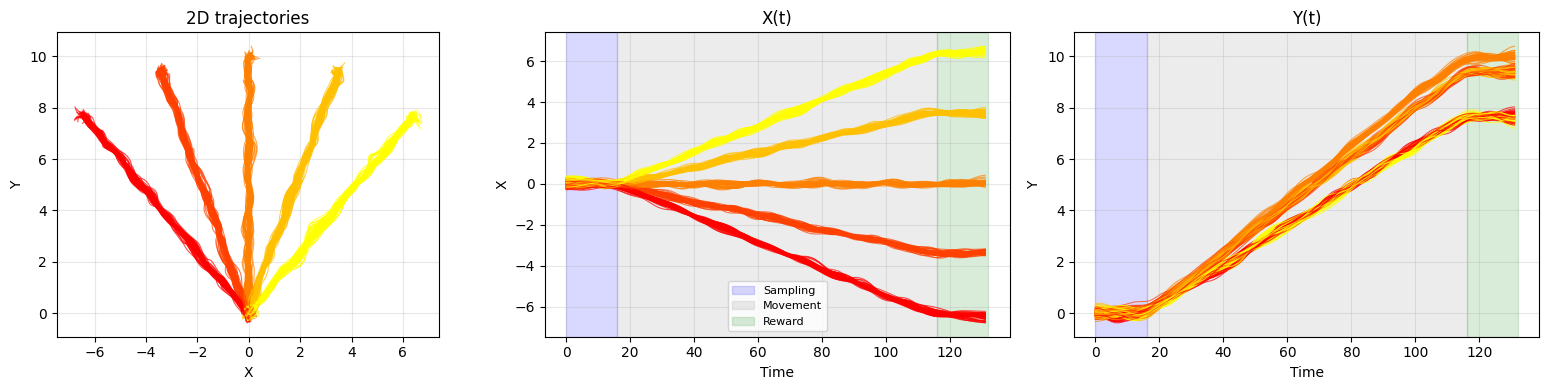

K = 5   spacing = 20 deg   endpoint angles = [130. 110.  90.  70.  50.]
T_TOTAL = 132   GO_STEP = 16   N_IN = 3
trials: train 14746  val 1638  test 4096   per-direction (all) [4096 4096 4096 4096 4096]
test per-direction: [809 825 821 827 814]


In [8]:
DATA = {K_MAIN: build_data(K_MAIN, plot=True)}
LOAD = {K_MAIN: make_loaders(DATA[K_MAIN])}

_d, _l = DATA[K_MAIN], LOAD[K_MAIN]
print(f"K = {_d['K']}   spacing = {SPACING_DEG} deg   "
      f"endpoint angles = {np.round(_d['theta_deg'], 2)}")
print(f"T_TOTAL = {_d['T_TOTAL']}   GO_STEP = {_d['GO_STEP']}   N_IN = {_d['N_IN']}")
print(f"trials: train {len(_l['train'].dataset)}  val {len(_l['val'].dataset)}  "
      f"test {len(_l['test'].dataset)}   per-direction (all) {np.bincount(_d['dirs'])}")
print(f"test per-direction: {np.bincount(_l['dirs_test'], minlength=_d['K'])}")

## **MODEL DEFINITION**


In [9]:
class RNN(nn.Module):
    def __init__(self, n_in, n_h, n_out, seed=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.alpha = 0.2
        self.noise = 0.2
        self.noisy_eval = False     # True keeps the recurrent noise on in eval mode (display passes only)
        self.W_ih  = nn.Parameter(0.1 * torch.randn(n_h, n_in))
        self.b_ih  = nn.Parameter(torch.zeros(n_h))
        self.W_hh  = nn.Parameter(0.1 * torch.randn(n_h, n_h))
        self.b_hh  = nn.Parameter(torch.zeros(n_h))
        self.W_out = nn.Parameter(0.1 * torch.randn(n_out, n_h))
        self.b_out = nn.Parameter(torch.zeros(n_out))
        self.register_buffer("mask", (torch.rand(n_h, n_h) < 0.8).float())
        self.n_h = n_h

    def forward(self, X):
        T, B, _ = X.shape
        x = (torch.rand(B, self.n_h, device=X.device) - 0.5) * 0.2
        r = torch.tanh(x)
        H, O = [], []
        for t in range(T):
            noise = self.noise * torch.randn_like(x) if (self.training or self.noisy_eval) else 0.0
            dx = -x + r @ (self.W_hh * self.mask).T + X[t] @ self.W_ih.T + self.b_hh + self.b_ih + noise
            x  = x + self.alpha * dx
            r  = torch.tanh(x)
            H.append(r); O.append(r @ self.W_out.T + self.b_out)
        return torch.stack(O), torch.stack(H)

def eval_t0(go_step):
    """First time step of the validation / test / stopping window."""
    return 0 if EVAL_WINDOW == "full" else go_step

def mse_loss(out, tgt, t0):
    """Sum of squared error from t0 onward, / (2 * B * (T - t0))."""
    return (tgt[t0:] - out[t0:]).pow(2).sum() / (2 * out.shape[1] * (out.shape[0] - t0))

def to_device(X, Y, dev):
    return X.permute(1, 0, 2).to(dev), Y.permute(1, 0, 2).to(dev)

def corr_penalty(hid, dirs, reduce=None, kind=None):
    """Differentiable sum (or mean) over direction pairs of |Pearson r|.
      kind="population": each direction's averaged activity flattened to one T*N vector, one |r| per pair.
      kind="unit":       per unit, r between the two directions' averaged time courses,
                         |r| averaged over units, then summed over pairs.
      reduce="sum" scales as C(K,2); reduce="mean" is the per-pair average, comparable across K.
    """
    reduce = PENALTY_REDUCE if reduce is None else reduce
    kind   = PENALTY_KIND if kind is None else kind
    ks = torch.unique(dirs)
    if ks.numel() < 2:
        return hid.sum() * 0.0
    iu = torch.triu_indices(ks.numel(), ks.numel(), offset=1)
    if kind == "population":
        M  = torch.stack([hid[:, dirs == k, :].mean(1).reshape(-1) for k in ks])
        Mc = M - M.mean(dim=1, keepdim=True)
        cov = Mc @ Mc.t()
        d   = torch.sqrt(torch.clamp(torch.diag(cov), min=1e-12))
        C   = cov / (d[:, None] * d[None, :] + 1e-8)
    elif kind == "unit":
        A  = torch.stack([hid[:, dirs == k, :].mean(1) for k in ks])        # (K, T, N)
        Ac = A - A.mean(dim=1, keepdim=True)                                # centre each unit over time
        Z  = Ac / torch.sqrt(torch.clamp((Ac ** 2).sum(1, keepdim=True), min=1e-12))
        C  = torch.einsum("itn,jtn->ijn", Z, Z).abs().mean(-1)              # (K, K): |r| averaged over units
    else:
        raise ValueError(f"PENALTY_KIND must be 'population' or 'unit', got {kind!r}")
    vals = C[iu[0], iu[1]].abs()
    return vals.sum() if reduce == "sum" else vals.mean()

def corr_matrix_np(A, kind=None):
    """(K, T, N) direction-averaged activity -> (K, K) matrix.
    population: signed Pearson r of the flattened T*N vectors.
    unit:       |r| per unit, averaged over units (non-negative)."""
    kind = PENALTY_KIND if kind is None else kind
    A = np.asarray(A, float)
    if kind == "population":
        return np.corrcoef(A.reshape(A.shape[0], -1))
    Ac = A - A.mean(axis=1, keepdims=True)
    Z  = Ac / np.sqrt(np.maximum((Ac ** 2).sum(axis=1, keepdims=True), 1e-12))
    return np.abs(np.einsum("itn,jtn->ijn", Z, Z)).mean(-1)

def corr_penalty_np(hid, dirs, reduce=None, kind=None):
    """Numpy twin. MEASUREMENT only -- never differentiated."""
    reduce = PENALTY_REDUCE if reduce is None else reduce
    ks = np.unique(dirs)
    if len(ks) < 2: return 0.0
    A = np.stack([hid[:, dirs == k, :].mean(1) for k in ks])
    C = corr_matrix_np(A, kind)
    v = np.abs(C[np.triu_indices(len(ks), 1)])
    return float(v.sum() if reduce == "sum" else v.mean())

@torch.no_grad()
def collect(model, loader, dev, t0, K, want_hidden=False):
    """Eval-mode pass. Returns loss, and optionally direction-averaged hidden
    activity (K, T, n_h) plus one representative trial per direction."""
    model.eval()
    loss, nb = 0.0, 0
    sums = None; counts = None; first_trial = None; dirs_all = []
    for X, Y, Dd in loader:
        X, Y = to_device(X, Y, dev)
        o, h = model(X)
        loss += mse_loss(o, Y, t0).item(); nb += 1
        if want_hidden:
            hc = h.cpu().numpy()                     # (T, b, n_h)
            dd = Dd.numpy()
            if sums is None:
                T_, _, NH_ = hc.shape
                sums   = np.zeros((K, T_, NH_), dtype=np.float64)
                counts = np.zeros(K, dtype=np.int64)
                first_trial = np.full((K, T_, NH_), np.nan, dtype=np.float32)
            for k in range(K):
                m = dd == k
                if m.any():
                    sums[k] += hc[:, m, :].sum(1); counts[k] += int(m.sum())
                    if np.isnan(first_trial[k, 0, 0]):
                        first_trial[k] = hc[:, np.where(m)[0][0], :]
            dirs_all.append(dd)
    out = {"loss": loss / max(nb, 1)}
    if want_hidden:
        assert (counts > 0).all(), f"some direction absent from this loader: {counts}"
        out["hid_dir_mean"] = (sums / counts[:, None, None]).astype(np.float32)
        out["hid_trial"]    = first_trial
        out["n_per_dir"]    = counts
    return out

## **TRAINING**

In [10]:
def train_run(K, seed, cond, print_every=100, t_start=None):
    D, L = DATA[K], LOAD[K]
    t0_train = LOSS_T0          # training objective window (0 = whole trial)
    t0_eval  = eval_t0(D["GO_STEP"])
    max_ep  = MAX_EPOCHS_BY_K[K]
    use_pen = (cond == "con")

    m   = RNN(D["N_IN"], N_H, 2, seed=seed).to(DEV)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    log = {"tr": [], "val": [], "test": [], "pen": []}
    incomplete_batches = 0
    streak, stop_ep = 0, None

    for ep in range(max_ep):
        m.train(); tr = pen = 0.0; nb = 0
        for X, Y, Dd in L["train"]:
            X, Y = to_device(X, Y, DEV); Dd = Dd.to(DEV)
            if Dd.unique().numel() < K:
                incomplete_batches += 1
            opt.zero_grad()
            o, h = m(X)
            l = mse_loss(o, Y, t0_train)
            p = corr_penalty(h, Dd)
            (l + ALPHA * p if use_pen else l).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), CLIP)
            opt.step()
            tr += l.item(); pen += p.item(); nb += 1

        vl = collect(m, L["val"], DEV, t0_eval, K)["loss"]
        te = collect(m, L["test"], DEV, t0_eval, K)["loss"]
        log["tr"].append(tr / nb); log["pen"].append(pen / nb)
        log["val"].append(vl); log["test"].append(te)

        if print_every and (ep % print_every == 0):
            el = f"  [{(time.time()-t_start)/60:.1f} min]" if t_start else ""
            print(f"    K{K} s{seed} {cond}  ep {ep+1:5d}/{max_ep}   "
                  f"MSE {tr/nb:.5f}  val {vl:.5f}  test {te:.5f}  "
                  f"|r|_{PENALTY_REDUCE} {pen/nb:7.3f}{el}")

        if THETA_STOP is not None:
            streak = streak + 1 if vl <= THETA_STOP else 0
            if streak >= STOP_PATIENCE:
                stop_ep = ep + 2 - STOP_PATIENCE
                print(f"    K{K} s{seed} {cond}  STOP at ep {stop_ep}/{max_ep}  "
                      f"val {vl:.6f} <= theta {THETA_STOP:.6f}")
                break
    else:
        if THETA_STOP is not None:
            print(f"    !! K{K} s{seed} {cond}  hit the {max_ep}-epoch CAP without reaching ")

    tr_f = collect(m, L["train"], DEV, t0_eval, K)
    va_f = collect(m, L["val"], DEV, t0_eval, K)
    te_f = collect(m, L["test"], DEV, t0_eval, K, want_hidden=True)

    Hcorr = te_f["hid_dir_mean"]
    Ccorr = corr_matrix_np(Hcorr)            # (K, K) per PENALTY_KIND
    iu = np.triu_indices(K, 1)
    mean_abs_r = float(np.mean(np.abs(Ccorr[iu]))) if K > 1 else np.nan
    mean_signed_r = float(np.mean(Ccorr[iu])) if K > 1 else np.nan

    log.update(
        K=K, seed=seed, cond=cond, alpha=ALPHA, penalty_reduce=PENALTY_REDUCE, penalty_kind=PENALTY_KIND,
        lr=LR, n_h=N_H, max_epochs=max_ep, cfg_hash=CFG_HASH,
        theta_stop=THETA_STOP, stop_patience=STOP_PATIENCE,
        stop_epoch=stop_ep if stop_ep is not None else len(log["val"]),
        reached_theta=(stop_ep is not None) or THETA_STOP is None,
        epochs_run=len(log["val"]),
        train_eval=tr_f["loss"], val_eval=va_f["loss"], test_eval=te_f["loss"],
        incomplete_batches=incomplete_batches,
        corr_sum=corr_penalty_np(
            te_f["hid_dir_mean"].transpose(1, 0, 2), np.arange(K), reduce="sum"
        ),
        mean_abs_pearson_r=mean_abs_r,
        mean_signed_pearson_r=mean_signed_r,
    )

    np.savez_compressed(hid_path(K, seed, cond),hid_dir_mean=te_f["hid_dir_mean"],hid_trial=te_f["hid_trial"],n_per_dir=te_f["n_per_dir"],go_step=D["GO_STEP"],theta_deg=D["theta_deg"],)

    if K == K_MAIN:
        checkpoint = {
            "model_state_dict": {name: tensor.detach().cpu()
                                 for name, tensor in m.state_dict().items()},
            "K": K,
            "seed": seed,
            "cond": cond,
            "n_in": D["N_IN"],
            "n_h": N_H,
            "n_out": 2,
            "alpha": ALPHA,
            "penalty_reduce": PENALTY_REDUCE, "penalty_kind": PENALTY_KIND,
            "lr": LR,
            "clip": CLIP,
            "cfg_hash": CFG_HASH,
            "loss_t0": LOSS_T0,
            "train_history_window": f"t >= {LOSS_T0} (train mode, whole trial)",
            "eval_t0": t0_eval,
            "eval_window": f"t >= {t0_eval} (" + ("whole trajectory" if t0_eval == 0 else "movement epoch") + ")",
            "theta_stop": THETA_STOP,
            "theta_hi": THETA_HI,
            "stop_patience": STOP_PATIENCE,
            "stop_epoch": log["stop_epoch"],
            "reached_theta": log["reached_theta"],
            "train_mse": float(tr_f["loss"]),
            "val_mse": float(va_f["loss"]),
            "test_mse": float(te_f["loss"]),
            "mean_abs_pearson_r": mean_abs_r,
            "mean_signed_pearson_r": mean_signed_r,
            "corr_penalty_sum": float(log["corr_sum"]),
            "train_history": np.asarray(log["tr"], dtype=np.float32),
            "val_history": np.asarray(log["val"], dtype=np.float32),
            "test_history": np.asarray(log["test"], dtype=np.float32),
            "penalty_history": np.asarray(log["pen"], dtype=np.float32),
        }
        torch.save(checkpoint, model_path(K, seed, cond))

        summary = {
            "K": int(K),
            "seed": int(seed),
            "condition": LAB[cond],
            "condition_code": cond,
            "epochs_run": int(log["epochs_run"]),
            "stop_epoch": int(log["stop_epoch"]),
            "reached_theta": bool(log["reached_theta"]),
            "theta_stop": float(THETA_STOP) if THETA_STOP is not None else None,
            "loss_t0": int(LOSS_T0),
            "eval_t0": int(t0_eval),
            "theta_hi": float(THETA_HI) if THETA_HI is not None else None,
            "train_mse": float(tr_f["loss"]),
            "validation_mse": float(va_f["loss"]),
            "test_mse": float(te_f["loss"]),
            "mean_abs_pearson_r": mean_abs_r,
            "mean_signed_pearson_r": mean_signed_r,
            "corr_penalty_sum": float(log["corr_sum"]),
            "model_file": str(model_path(K, seed, cond)),
            "run_file": str(run_path(K, seed, cond)),
            "hidden_file": str(hid_path(K, seed, cond)),
        }
        with open(summary_path(K, seed, cond), "w") as f:
            json.dump(summary, f, indent=2)

        print(f" saved main-study model -> {model_path(K, seed, cond).name}")

    return log

def _run_is_cached(K, seed, cond):
    base = run_path(K, seed, cond).exists() and hid_path(K, seed, cond).exists()
    if K == K_MAIN:
        base = base and model_path(K, seed, cond).exists() and summary_path(K, seed, cond).exists()
    return base

def run_study(Ks, seeds=SEEDS, conds=CONDS, print_every=100):
    t_start = time.time(); n_new = 0
    todo = [(K, s, c) for K in Ks for s in seeds for c in conds
            if not _run_is_cached(K, s, c)]
    print(f"{len(Ks)*len(seeds)*len(conds) - len(todo)} cached, {len(todo)} to train.")

    for K in Ks:
        if K not in DATA:
            DATA[K] = build_data(K); LOAD[K] = make_loaders(DATA[K])
        for seed in seeds:
            for cond in conds:
                if _run_is_cached(K, seed, cond):
                    continue
                print(f"\n=== K={K}  seed={seed}  {LAB[cond]} ===")
                log = train_run(K, seed, cond, print_every=print_every, t_start=t_start)
                with open(run_path(K, seed, cond), "wb") as f:
                    pickle.dump(log, f)

                n_new += 1
                done, left = n_new, len(todo) - n_new
                el = (time.time() - t_start) / 60
                how = (f"stopped at ep {log['stop_epoch']}" if log["reached_theta"]
                       else f"CENSORED at cap {log['max_epochs']}")
                print(f"  -> {how}. val {log['val'][-1]:.6f}  "
                      f"test_eval {log['test_eval']:.5f}  "
                      f"[{el:.1f} min elapsed, ~{el/done*left:.0f} min left]")

    print(f"\nfinished in {(time.time()-t_start)/60:.1f} min")

def load_runs(Ks=None, seeds=SEEDS, conds=CONDS):
    out = {}
    for p in sorted(RUNDIR.glob("K*_s*_*.pkl")):
        with open(p, "rb") as f:
            r = pickle.load(f)
        if Ks is not None and r["K"] not in Ks:
            continue
        if r["seed"] not in seeds or r["cond"] not in conds:
            continue
        out[(r["K"], r["seed"], r["cond"])] = r
    return out

In [11]:
def save_main_study_exports():
    runs = load_runs(Ks=[K_MAIN])

    expected = len(SEEDS) * len(CONDS)
    if len(runs) != expected:
        raise RuntimeError(
            f"Expected {expected} K={K_MAIN} main-study runs, found {len(runs)}. "
            "Run the MAIN STUDY cell first."
        )

    result_rows = []
    history_rows = []
    corr_rows = []

    for (K, seed, cond), r in sorted(runs.items()):
        z = np.load(hid_path(K, seed, cond))
        H = z["hid_dir_mean"]
        C = corr_matrix_np(H)
        iu = np.triu_indices(K, 1)

        mean_abs_r = float(np.mean(np.abs(C[iu]))) if K > 1 else np.nan
        mean_signed_r = float(np.mean(C[iu])) if K > 1 else np.nan

        result_rows.append({
            "K": K,
            "seed": seed,
            "condition": LAB[cond],
            "condition_code": cond,
            "epochs_run": r["epochs_run"],
            "stop_epoch": r["stop_epoch"],
            "reached_theta": r["reached_theta"],
            "loss_t0": LOSS_T0,
            "eval_window": EVAL_WINDOW,
            "train_mse": r["train_eval"],          
            "validation_mse": r["val_eval"],
            "test_mse": r["test_eval"],
            "mean_abs_pearson_r": mean_abs_r,
            "mean_signed_pearson_r": mean_signed_r,
            "corr_penalty_sum": r["corr_sum"],
            "model_file": str(model_path(K, seed, cond)),
            "run_file": str(run_path(K, seed, cond)),
            "hidden_file": str(hid_path(K, seed, cond)),
        })

        for ep, (tr, va, te) in enumerate(zip(r["tr"], r["val"], r["test"]), start=1):
            history_rows.append({
                "K": K,
                "seed": seed,
                "condition": LAB[cond],
                "condition_code": cond,
                "epoch": ep,
                "train_loss_whole_trial": tr,     
                "validation_mse": va,             
                "test_mse": te,                   
            })

        for i, j in zip(iu[0], iu[1]):
            corr_rows.append({
                "K": K,
                "seed": seed,
                "condition": LAB[cond],
                "condition_code": cond,
                "direction_i": int(i),
                "direction_j": int(j),
                "pearson_r": float(C[i, j]),
                "abs_pearson_r": float(abs(C[i, j])),
            })

    main_results = pd.DataFrame(result_rows)
    loss_history = pd.DataFrame(history_rows)
    correlations = pd.DataFrame(corr_rows)

    results_csv = SUMMARYDIR / "main_study_results.csv"
    losses_csv = SUMMARYDIR / "main_study_loss_history.csv"
    corr_csv = SUMMARYDIR / "main_study_correlations.csv"

    main_results.to_csv(results_csv, index=False)
    loss_history.to_csv(losses_csv, index=False)
    correlations.to_csv(corr_csv, index=False)

    manifest = {
        "cfg_hash": CFG_HASH,
        "K_main": int(K_MAIN),
        "spacing_deg": float(SPACING_DEG),
        "n_seeds": len(SEEDS),
        "conditions": [LAB[c] for c in CONDS],
        "theta_stop": float(THETA_STOP) if THETA_STOP is not None else None,
        "theta_hi": float(THETA_HI) if THETA_HI is not None else None,
        "theta_source": THETA_SOURCE,
        "models_dir": str(MODELDIR),
        "results_csv": str(results_csv),
        "loss_history_csv": str(losses_csv),
        "correlations_csv": str(corr_csv),
    }

    with open(SUMMARYDIR / "main_study_manifest.json", "w") as f:
        json.dump(manifest, f, indent=2)

    print("\nMAIN STUDY SAVED")
    print("folder       ->", MAIN_STUDY_DIR)
    print("models       ->", MODELDIR)
    print("final metrics->", results_csv)
    print("loss history ->", losses_csv)
    print("correlations ->", corr_csv)

    display(main_results)
    return main_results, loss_history, correlations

## **TRAINING RUNS**

In [12]:
run_study([K_MAIN], print_every=100)

MAIN_RESULTS, MAIN_LOSS_HISTORY, MAIN_CORRELATIONS = save_main_study_exports()

0 cached, 20 to train.

=== K=5  seed=42  Control ===
    K5 s42 std  ep     1/2500   MSE 0.40220  val 0.03582  test 0.03627  |r|_sum   7.709  [0.2 min]
    K5 s42 std  STOP at ep 41/2500  val 0.019380 <= theta 0.020000
 saved main-study model -> K5_s42_std.pt
  -> stopped at ep 41. val 0.019380  test_eval 0.01975  [8.8 min elapsed, ~167 min left]

=== K=5  seed=42  Constrained ===
    K5 s42 con  ep     1/2500   MSE 0.55920  val 0.11732  test 0.11599  |r|_sum   1.979  [9.0 min]
    K5 s42 con  ep   101/2500   MSE 0.02408  val 0.02108  test 0.02140  |r|_sum   0.050  [31.2 min]
    K5 s42 con  ep   201/2500   MSE 0.02155  val 0.01973  test 0.02000  |r|_sum   0.033  [53.5 min]
    K5 s42 con  STOP at ep 197/2500  val 0.019732 <= theta 0.020000
 saved main-study model -> K5_s42_con.pt
  -> stopped at ep 197. val 0.019732  test_eval 0.02001  [53.5 min elapsed, ~482 min left]

=== K=5  seed=123  Control ===
    K5 s123 std  ep     1/2500   MSE 0.35614  val 0.03143  test 0.03167  |r|_sum   7

,K,seed,condition,condition_code,epochs_run,stop_epoch,reached_theta,loss_t0,eval_window,train_mse,validation_mse,test_mse,mean_abs_pearson_r,mean_signed_pearson_r,corr_penalty_sum,model_file,run_file,hidden_file
0,5,7,Constrained,con,177,173,True,0,full,0.019608,0.019408,0.019746,0.002150,0.002150,0.021500,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s7_con.pkl,results_k5_20deg/hidden_6391673deb/K5_s7_con.npz
1,5,7,Control,std,51,47,True,0,full,0.019321,0.019191,0.019473,0.684690,0.684690,6.846901,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s7_std.pkl,results_k5_20deg/hidden_6391673deb/K5_s7_std.npz
2,5,13,Constrained,con,104,100,True,0,full,0.020282,0.020020,0.020385,0.003371,0.003371,0.033709,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s13_con.pkl,results_k5_20deg/hidden_6391673deb/K5_s13_con.npz
3,5,13,Control,std,50,46,True,0,full,0.019301,0.019172,0.019401,0.727608,0.727608,7.276081,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s13_std.pkl,results_k5_20deg/hidden_6391673deb/K5_s13_std.npz
4,5,42,Constrained,con,201,197,True,0,full,0.019917,0.019785,0.020011,0.002548,0.002548,0.025477,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s42_con.pkl,results_k5_20deg/hidden_6391673deb/K5_s42_con.npz
5,5,42,Control,std,45,41,True,0,full,0.019637,0.019388,0.019754,0.699874,0.699874,6.998743,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s42_std.pkl,results_k5_20deg/hidden_6391673deb/K5_s42_std.npz
6,5,123,Constrained,con,129,125,True,0,full,0.020004,0.019841,0.020045,0.003657,0.003657,0.036573,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s123_con.pkl,results_k5_20deg/hidden_6391673deb/K5_s123_con...
7,5,123,Control,std,55,51,True,0,full,0.019893,0.019704,0.019994,0.693187,0.693187,6.931866,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s123_std.pkl,results_k5_20deg/hidden_6391673deb/K5_s123_std...
8,5,456,Constrained,con,188,184,True,0,full,0.019451,0.019314,0.019536,0.002255,0.002255,0.022554,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s456_con.pkl,results_k5_20deg/hidden_6391673deb/K5_s456_con...
9,5,456,Control,std,53,49,True,0,full,0.019983,0.019787,0.020143,0.693956,0.693956,6.939558,results_k5_20deg/main_study_6391673deb/models/...,results_k5_20deg/runs_6391673deb/K5_s456_std.pkl,results_k5_20deg/hidden_6391673deb/K5_s456_std...


## **Evaluation**

In [13]:
RUNS = load_runs()
print(f"{len(RUNS)} runs loaded from {RUNDIR}")
print(pd.Series([f"K{k} {LAB[c]}" for (k, s, c) in RUNS]).value_counts().to_string())

STOPS = pd.DataFrame([dict(K=k[0], seed=k[1], model=LAB[k[2]],
                           stop_epoch=r["stop_epoch"], cap=r["max_epochs"],
                           val_at_stop=float(r["val"][-1]),
                           test_at_stop=float(r["test"][-1]))
                      for k, r in RUNS.items()]).sort_values(["K", "model", "seed"])
print(f"\nstopping epochs (theta = {THETA_STOP:.6f}):")
print(STOPS.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

20 runs loaded from results_k5_20deg/runs_6391673deb
K5 Constrained    10
K5 Control        10

stopping epochs (theta = 0.020000):
 K   seed       model  stop_epoch  cap  val_at_stop  test_at_stop
 5      7 Constrained         173 2500     0.019415      0.019757
 5     13 Constrained         100 2500     0.019983      0.020364
 5     42 Constrained         197 2500     0.019732      0.020000
 5    123 Constrained         125 2500     0.019798      0.020063
 5    456 Constrained         184 2500     0.019316      0.019511
 5    777 Constrained         143 2500     0.019296      0.019541
 5    999 Constrained         121 2500     0.019689      0.019950
 5   2023 Constrained         158 2500     0.019466      0.019733
 5  31415 Constrained         107 2500     0.019717      0.020008
 5 271828 Constrained         132 2500     0.019807      0.020014
 5      7     Control          47 2500     0.019173      0.019466
 5     13     Control          46 2500     0.019162      0.019408
 5     42 

## **1. Hidden Activations**

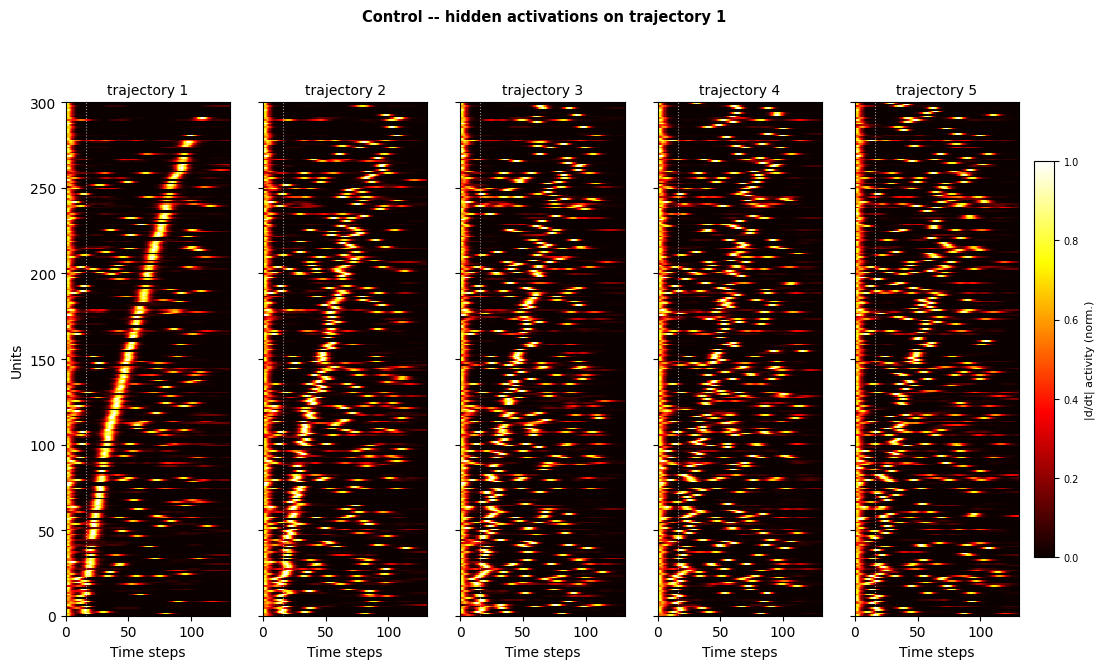

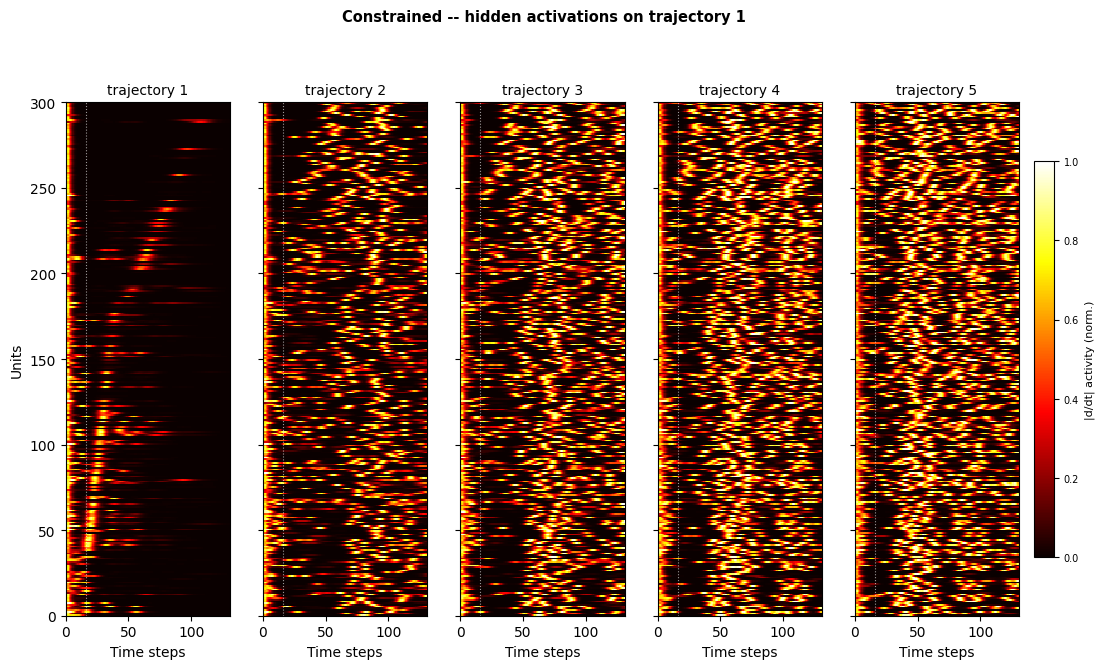

In [14]:
SEED_FOR_MAPS = SEEDS[0]

def load_hidden(K, seed, cond):
    z = np.load(hid_path(K, seed, cond))
    return {k: z[k] for k in z.files}

def flip_rate(H, sigma=SMOOTH_SIGMA):
    D = np.abs(np.diff(H, axis=1))
    D = gaussian_filter1d(D, sigma=sigma, axis=1, mode="nearest")
    mn = D.min(axis=(0, 1), keepdims=True)
    mx = D.max(axis=(0, 1), keepdims=True)
    return (D - mn) / np.maximum(mx - mn, 1e-12)

def transition_order(R, go_step, ref=REF_DIR, window=SORT_T0):
    t0 = go_step if window == "post_go" else 0
    return np.argsort(np.argmax(R[ref, t0:, :], axis=0))

def plot_maps(R, order, go_step, title, fname, col_prefix="trajectory"):
    K_, T_, NH_ = R.shape
    h = max(3.6, NH_ / 45)
    fig, axes = plt.subplots(1, K_, figsize=(2.35 * K_ + 1.0, h), sharey=True)
    axes = np.atleast_1d(axes)
    for k, ax in enumerate(axes):
        im = ax.imshow(R[k][:, order].T, aspect="auto", origin="lower",
                       cmap=HEAT_CMAP, vmin=0, vmax=1,
                       extent=[0, T_, 0, NH_], interpolation="nearest")
        ax.axvline(go_step, color="w", lw=0.8, ls=":", alpha=.6)
        ax.set_title(f"{col_prefix} {k+1}", fontsize=10)
        ax.set_xlabel("Time steps")
    axes[0].set_ylabel("Units")
    cb = fig.colorbar(im, ax=axes.tolist(), fraction=0.02, pad=0.015)
    cb.set_label("|d/dt| activity (norm.)", fontsize=8)
    cb.ax.tick_params(labelsize=7)
    fig.suptitle(title, fontsize=10.5, fontweight="bold", y=1.02)
    savefig(fig, fname); display(fig); plt.close(fig)

Hs  = {c: load_hidden(K_MAIN, SEED_FOR_MAPS, c) for c in CONDS}
GO  = int(Hs["std"]["go_step"])
RATE = {c: flip_rate(Hs[c]["hid_dir_mean"]) for c in CONDS}
ORD = {c: transition_order(RATE[c], GO) for c in CONDS}

for c in CONDS:
    plot_maps(RATE[c], ORD[c], GO,
              f"{LAB[c]} -- hidden activations "
              f"on trajectory {REF_DIR+1}",
              f"fig02_maps_{c}_fliprate")

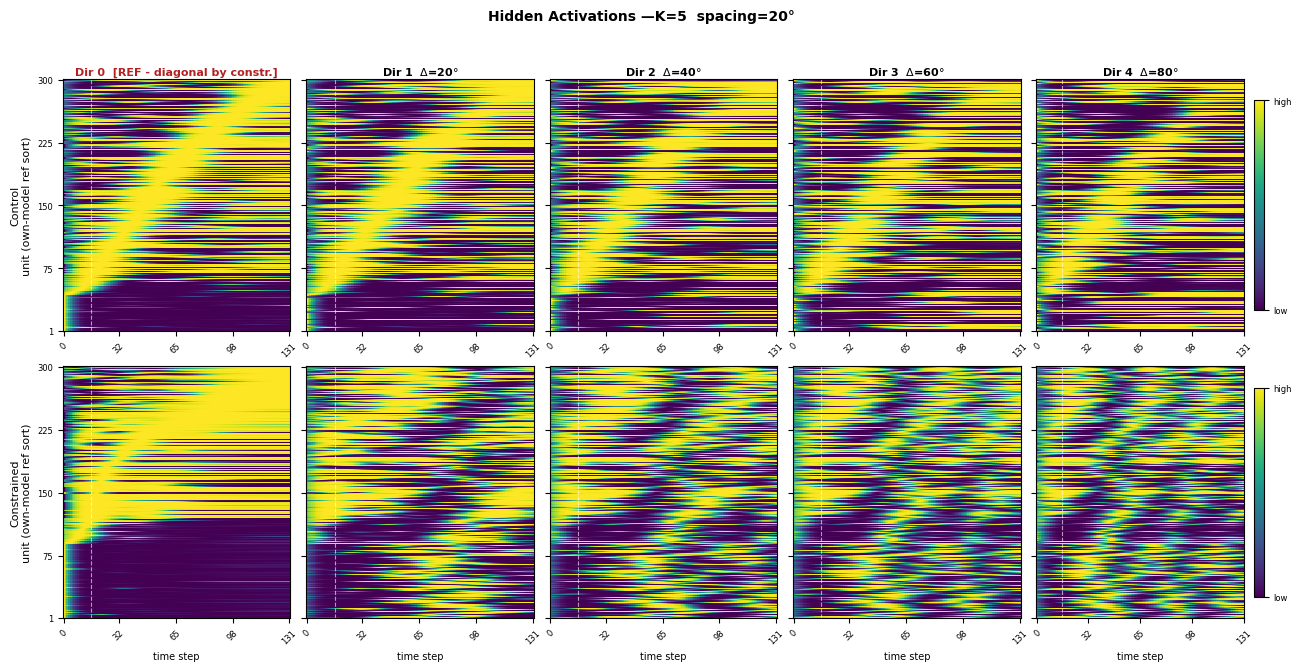

In [15]:
import matplotlib.gridspec as gridspec

SEED_FOR_MAPS = SEEDS[0]
D = DATA[K_MAIN]; GO = D["GO_STEP"]; theta = D["theta_deg"]

SIGMA_TWOPANEL = 4

def _norm(H, sigma=SIGMA_TWOPANEL):
    """Per-unit min-max over time. H is (n_h, T): smoothing runs along axis 1."""
    Hs = gaussian_filter1d(H, sigma=sigma, axis=1, mode="nearest")
    mn = Hs.min(axis=1, keepdims=True)
    mx = Hs.max(axis=1, keepdims=True)
    return (Hs - mn) / np.maximum(mx - mn, 1e-12)

def _sort_ref(Hdm, ref=REF_DIR):
    return _norm(Hdm[ref].T).argmax(1).argsort()

Hs = {c: np.load(hid_path(K_MAIN, SEED_FOR_MAPS, c))["hid_dir_mean"] for c in CONDS}
SRT = {c: _sort_ref(Hs[c]) for c in CONDS}
nc, n_h, T = K_MAIN, Hs["std"].shape[2], Hs["std"].shape[1]

fig = plt.figure(figsize=(max(3.1 * nc, 11), 7))
gh = gridspec.GridSpec(2, nc, figure=fig, hspace=0.14, wspace=0.07)
for row, c in enumerate(CONDS):
    for col in range(nc):
        ax = fig.add_subplot(gh[row, col])
        im = ax.imshow(_norm(Hs[c][col].T)[SRT[c]], aspect="auto", cmap="viridis",
                       vmin=0, vmax=1, origin="lower", interpolation="nearest")
        ax.axvline(GO, color="white", lw=0.8, ls="--", alpha=0.6)
        xt = np.linspace(0, T - 1, 5, dtype=int)
        ax.set_xticks(xt); ax.set_xticklabels(xt, fontsize=6, rotation=45)
        yt = np.linspace(0, n_h - 1, 5, dtype=int); ax.set_yticks(yt)
        ax.set_yticklabels((yt + 1) if col == 0 else [""] * len(yt), fontsize=6)
        if row == 1: ax.set_xlabel("time step", fontsize=7)
        if col == 0: ax.set_ylabel(f"{LAB[c]}\nunit (own-model ref sort)", fontsize=8)
        if row == 0:
            is_ref = col == REF_DIR
            tag = "  [REF - diagonal by constr.]" if is_ref else \
                  f"  $\\Delta$={abs(theta[col]-theta[REF_DIR]):.0f}$\\degree$"
            ax.set_title(f"Dir {col}{tag}", fontsize=8, fontweight="bold", pad=3,
                         color="firebrick" if is_ref else "k")
        if col == nc - 1:
            cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cb.set_ticks([0, 1]); cb.set_ticklabels(["low", "high"]); cb.ax.tick_params(labelsize=6)

fig.suptitle(f"Hidden Activations —K={K_MAIN}  spacing={SPACING_DEG}\u00b0 ",
             fontsize=10, fontweight="bold", y=0.98)
savefig(fig, "fig02_maps_twopanel"); display(fig); plt.close(fig)

## **2. Loss Curves**

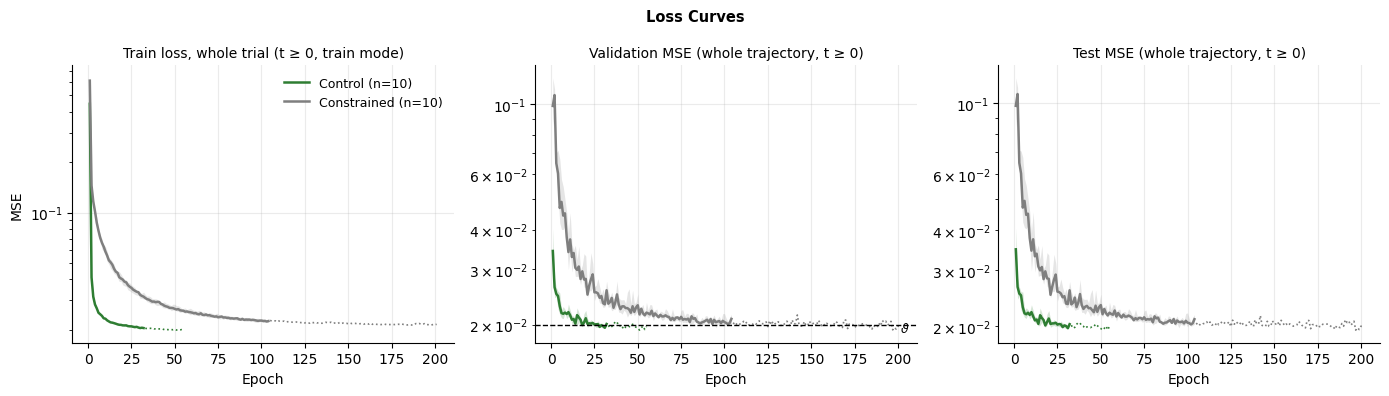

In [16]:
def curve_stack(K, cond, key, runs=None):
    runs = RUNS if runs is None else runs
    cs = [np.asarray(runs[(K, s, cond)][key], float) for s in SEEDS if (K, s, cond) in runs]
    n  = max(len(c) for c in cs)
    S  = np.full((len(cs), n), np.nan)
    for i, c in enumerate(cs):
        S[i, :len(c)] = c
    return S                                          

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, key, ttl in zip(axes, ["tr", "val", "test"],
                        [f"Train loss, whole trial (t ≥ {LOSS_T0}, train mode)",
                         f"Validation MSE ({'whole trajectory' if EVAL_WINDOW == 'full' else 'movement'}, t ≥ {eval_t0(DATA[K_MAIN]['GO_STEP'])})",
                         f"Test MSE ({'whole trajectory' if EVAL_WINDOW == 'full' else 'movement'}, t ≥ {eval_t0(DATA[K_MAIN]['GO_STEP'])})"]):
    for cond in CONDS:
        S = curve_stack(K_MAIN, cond, key)
        x = np.arange(1, S.shape[1] + 1)
        med = np.nanmedian(S, 0); q1, q3 = np.nanpercentile(S, [25, 75], axis=0)
        alive = np.sum(~np.isnan(S), 0)
        full  = alive == S.shape[0]
        ax.fill_between(x[full], q1[full], q3[full], color=COLOR[LAB[cond]], alpha=.20, lw=0)
        ax.plot(x[full], med[full], color=COLOR[LAB[cond]], lw=1.8,
                label=f"{LAB[cond]} (n={S.shape[0]})")
        if (~full).any():                 # tail where seeds have already stopped
            ax.plot(x[~full], med[~full], color=COLOR[LAB[cond]], lw=1.2, ls=":")
    if key == "val" and THETA_STOP is not None:
        ax.axhline(THETA_STOP, color="k", lw=1.0, ls="--")
        ax.text(0.98, 0.04, r"$\vartheta$", transform=ax.transAxes, ha="right", fontsize=9)
    ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_title(ttl, fontsize=10)
    ax.grid(alpha=.25); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("MSE"); axes[0].legend(frameon=False, fontsize=9)
fig.suptitle(f"Loss Curves",fontsize=10.5, fontweight="bold")
fig.tight_layout()
savefig(fig, "loss_curves"); display(fig); plt.close(fig)


## **3. Behavioral MSE Box plots** 

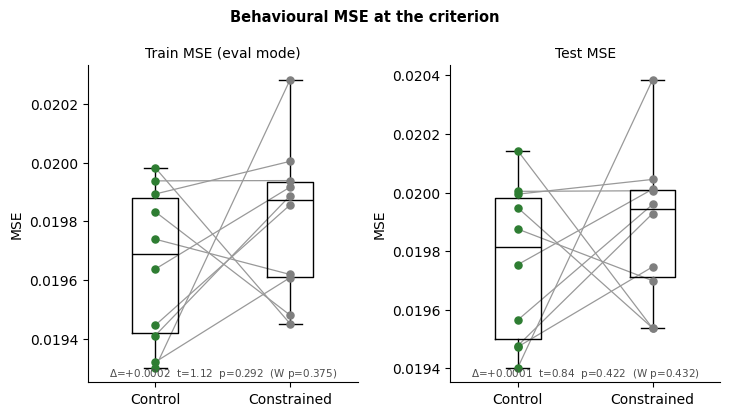

              train             val            test        
               mean     std    mean     std    mean     std
model                                                      
Constrained 0.01980 0.00026 0.01962 0.00026 0.01989 0.00026
Control     0.01965 0.00026 0.01949 0.00026 0.01976 0.00027

all three: eval mode, window t >= 0 (EVAL_WINDOW = full)
model
Constrained   1.004
Control       1.006


In [17]:
rows = [dict(seed=s, model=LAB[c],
             train=RUNS[(K_MAIN, s, c)]["train_eval"],
             val  =RUNS[(K_MAIN, s, c)]["val_eval"],
             test =RUNS[(K_MAIN, s, c)]["test_eval"])
        for s in SEEDS for c in CONDS if (K_MAIN, s, c) in RUNS]
MSE = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(7.4, 4.2))
for ax, key, ttl in zip(axes, ["train", "test"], ["Train MSE (eval mode)", "Test MSE"]):
    a = MSE[MSE.model == "Control"].set_index("seed")[key]
    b = MSE[MSE.model == "Constrained"].set_index("seed")[key]
    idx = a.index.intersection(b.index); a, b = a.loc[idx], b.loc[idx]
    for i in idx:
        ax.plot([0, 1], [a[i], b[i]], color="0.6", lw=.9, zorder=1)
    ax.boxplot([a.values, b.values], positions=[0, 1], widths=.34, showfliers=False,
               medianprops=dict(color="k"), zorder=2)
    ax.scatter(np.zeros(len(a)), a, color=C_CTL, s=26, zorder=3)
    ax.scatter(np.ones(len(b)),  b, color=C_CON, s=26, zorder=3)
    ax.set_xticks([0, 1], ["Control", "Constrained"])
    ax.set_ylabel("MSE"); ax.set_title(ttl, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    t, p = ttest_rel(b.values, a.values); _, pw = wilcoxon(b.values, a.values)
    d = (b.values - a.values)
    ax.text(.5, .02, f"$\\Delta$={d.mean():+.4f}  t={t:.2f}  p={p:.3g}  (W p={pw:.3g})",
            transform=ax.transAxes, ha="center", fontsize=7.5, color="0.3")
fig.suptitle(f"Behavioural MSE at the criterion",fontsize=10.5, fontweight="bold")
fig.tight_layout(); savefig(fig, "mse_boxplots")
display(fig); plt.close(fig)

print(MSE.groupby("model")[["train", "val", "test"]]
        .agg(["mean", "std"]).to_string(float_format=lambda x: f"{x:.5f}"))
gap = MSE.groupby("model")[["train", "val", "test"]].mean()
print(f"\nall three: eval mode, window t >= {eval_t0(DATA[K_MAIN]['GO_STEP'])} (EVAL_WINDOW = {EVAL_WINDOW})")
print((gap.test / gap.train).rename("test / train").to_string(float_format=lambda x: f"{x:.3f}"))


In [18]:
TRAJ_COLORS = plt.cm.autumn(np.linspace(0, 1, K_MAIN))   # C1 = dark red ... C5 = yellow

def ed_savefig(fig, name, exts=("png", "svg", "pdf")):
    for e in exts:
        fig.savefig(ED_FIGDIR / f"{name}.{e}", dpi=300, bbox_inches="tight")
    return ED_FIGDIR / f"{name}.png"

ED_DATA = DATA[K_MAIN]
GO_STEP, T_TOTAL = ED_DATA["GO_STEP"], ED_DATA["T_TOTAL"]

def ed_split_indices(D, seed=SPLIT_SEED):
    """Mirrors make_loaders(): same RandomState, same torch generator, same order."""
    N   = D["stim"].shape[0]
    idx = np.random.RandomState(seed).permutation(N)
    n_test   = int(TEST_FRAC * N)
    test_idx = idx[N - n_test:]
    tv_idx   = idx[:N - n_test]
    n_val = int(VAL_FRAC * len(tv_idx))
    g = torch.Generator().manual_seed(seed)
    tr_sub, va_sub = random_split(range(len(tv_idx)), [len(tv_idx) - n_val, n_val], generator=g)
    return dict(train=tv_idx[np.asarray(tr_sub.indices)], val=tv_idx[np.asarray(va_sub.indices)],
                test=test_idx, all=np.arange(N))

SPLITS = ed_split_indices(ED_DATA)
assert np.array_equal(SPLITS["test"], LOAD[K_MAIN]["test_idx"]), "test split differs from training"
IDX = SPLITS[SPLIT]

def mse_trialweighted(pred, targ, t0=None):
    """Training's normalisation (sum sq / (2 * B * (T - t0))), over all trials at once."""
    t0 = eval_t0(GO_STEP) if t0 is None else t0
    d = targ[:, t0:, :] - pred[:, t0:, :]
    return float((d ** 2).sum() / (2 * pred.shape[0] * (pred.shape[1] - t0)))

def mse_batchmean(pred, targ, t0=None, bs=BATCH_SIZE):
    """What training logged: mean over batches of per-batch means."""
    t0 = eval_t0(GO_STEP) if t0 is None else t0
    return float(np.mean([mse_trialweighted(pred[i:i + bs], targ[i:i + bs], t0)
                          for i in range(0, len(pred), bs)]))

In [19]:
def load_ckpt(path):
    """torch.load with a weights_only fallback for older/newer torch versions."""
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

def ckpt_path(seed, cond, K=K_MAIN):
    return MODELDIR / f"K{K}_s{seed}_{cond}.pt"

@torch.no_grad()
def extract(seed, cond, idx=None, eval_seed=EVAL_SEED, chunk=BATCH_SIZE, keep_hidden=True, noisy=False):
    """Returns predictions (N,T,2), labels (N,), hidden (N, n_units, T) and metadata.

    The labels are direction ids 0..K-1; direction k is trajectory / condition C{k+1}.
    """
    idx = IDX if idx is None else idx
    p   = ckpt_path(seed, cond)
    assert p.exists(), f"missing checkpoint: {p}"
    ck  = load_ckpt(p)

    assert ck["cfg_hash"] == CFG_HASH, (
        f"{p.name} was trained under config {ck['cfg_hash']} but this notebook rebuilds "
        f"{CFG_HASH}. The data or hyper-parameters differ — do not plot this.")
    assert ck["K"] == K_MAIN and ck["seed"] == seed and ck["cond"] == cond
    assert ck.get("eval_t0") == eval_t0(GO_STEP), f"{p.name}: trained with eval_t0={ck.get('eval_t0')}, expected {eval_t0(GO_STEP)}"
    assert ck.get("loss_t0") == LOSS_T0, f"{p.name}: trained with loss_t0={ck.get('loss_t0')}, expected {LOSS_T0}"

    m = RNN(ck["n_in"], ck["n_h"], ck["n_out"]).to(DEV)
    m.load_state_dict(ck["model_state_dict"])
    m.eval()
    m.noisy_eval = noisy

    stim = torch.from_numpy(ED_DATA["stim"][idx])
    torch.manual_seed(eval_seed)                      # pins the random initial state
    P, H = [], []
    for i in range(0, len(idx), chunk):
        X = stim[i:i + chunk].permute(1, 0, 2).to(DEV)
        o, h = m(X)
        P.append(o.permute(1, 0, 2).cpu().numpy())    # (b, T, 2)
        if keep_hidden:
            H.append(h.permute(1, 2, 0).cpu().numpy())  # (b, n_h, T)

    pred   = np.concatenate(P, 0).astype(np.float32)
    hidden = np.concatenate(H, 0).astype(np.float32) if keep_hidden else None
    labels = ED_DATA["dirs"][idx].astype(np.int64)
    targ   = ED_DATA["targ"][idx]

    out = dict(seed=seed, cond=cond, model=LAB[cond], pred=pred, labels=labels,
               targ=targ, hidden=hidden, ckpt=ck,
               stop_epoch=int(ck["stop_epoch"]),
               val_history=np.asarray(ck["val_history"], float),
               mse_trial=mse_trialweighted(pred, targ),
               mse_batch=mse_batchmean(pred, targ))
    if keep_hidden:
        out["hidden_dir_mean"] = np.stack([hidden[labels == k].mean(0) for k in range(K_MAIN)])
    return out

def dir_mean(hidden, labels, K=K_MAIN):
    """(N, n_units, T) -> (K, n_units, T), trial-averaged within each direction."""
    return np.stack([hidden[labels == k].mean(0) for k in range(K)])

def rsm(hidden_dir_mean):
    """(K, n_units, T) direction-averaged activity -> (K, K) similarity matrix,
    defined exactly as the training penalty is (PENALTY_KIND): signed Pearson r of the
    flattened T*N vectors ("population") or |r| averaged over units ("unit")."""
    return corr_matrix_np(hidden_dir_mean.transpose(0, 2, 1))

def offdiag_mean_abs(C):
    iu = np.triu_indices(C.shape[0], 1)
    return float(np.abs(C[iu]).mean())

In [20]:
RSM_PER_SEED = {c: {} for c in CONDS}
rows = []
for s in SEEDS:
    for c in CONDS:
        r = extract(s, c, keep_hidden=True)
        C = rsm(r["hidden_dir_mean"])
        RSM_PER_SEED[c][s] = C
        ck = r["ckpt"]
        rows.append(dict(
            seed=s, model=LAB[c], stop_epoch=r["stop_epoch"],
            reached_theta=bool(ck["reached_theta"]),
            mse_stored=float(ck["test_mse"]),
            mse_batchmean=r["mse_batch"], mse_trialweighted=r["mse_trial"],
            r_stored=float(ck["mean_abs_pearson_r"]), r_recomputed=offdiag_mean_abs(C),
            r_signed=float(np.mean(C[np.triu_indices(K_MAIN, 1)])),
            mse_hold=mse_trialweighted(r["pred"][:, :GO_STEP], r["targ"][:, :GO_STEP], t0=0),
            max_bias_hold=float(np.linalg.norm(np.stack([
                r["pred"][r["labels"] == k, :GO_STEP].mean(0) - r["targ"][r["labels"] == k, :GO_STEP].mean(0)
                for k in range(K_MAIN)]), axis=2).mean(0).max()),
        ))
        del r

SUMMARY = pd.DataFrame(rows).sort_values(["model", "seed"]).reset_index(drop=True)
SUMMARY["mse_gap_%"]  = 100 * (SUMMARY.mse_batchmean - SUMMARY.mse_stored).abs() / SUMMARY.mse_stored
SUMMARY["r_gap_abs"]  = (SUMMARY.r_recomputed - SUMMARY.r_stored).abs()

assert SUMMARY.reached_theta.all(), "a run never reached theta; it must not enter the figure"
assert len(SUMMARY) == len(SEEDS) * len(CONDS), "missing checkpoints"
assert SUMMARY["r_gap_abs"].max() < 0.01, \
    f"recomputed |r| drifts from the stored value by {SUMMARY['r_gap_abs'].max():.4f} — investigate"

## **4. Predicted Trajectories**

In [21]:
R = {c: extract(SEED_FIG, c, keep_hidden=True) for c in CONDS}
R_PRED = {c: extract(SEED_FIG, c, keep_hidden=False, noisy=PRED_NOISE) for c in CONDS}

assert R["std"]["pred"].shape == (len(IDX), T_TOTAL, 2)
assert R["std"]["hidden"].shape == (len(IDX), N_H, T_TOTAL)

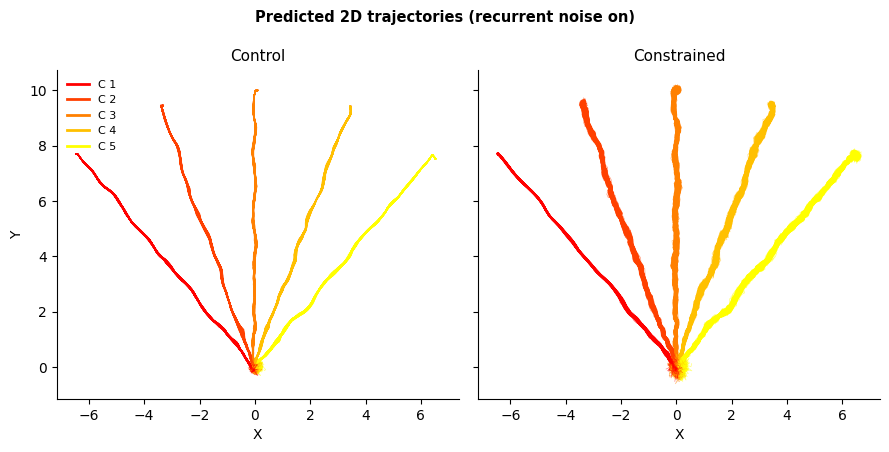

In [22]:
def fig_trajectories(R, show_target=False, lw=0.5, alpha=0.5, max_trials=None):
    fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.4), sharex=True, sharey=True)
    for ax, c in zip(axes, CONDS):
        P, L = R[c]["pred"], R[c]["labels"]
        n = len(P) if max_trials is None else min(max_trials, len(P))
        for i in range(n):
            ax.plot(P[i, :, 0], P[i, :, 1], color=TRAJ_COLORS[L[i]], lw=lw, alpha=alpha)
        if show_target:
            for k in range(K_MAIN):
                Tk = R[c]["targ"][L == k].mean(0)
                ax.plot(Tk[:, 0], Tk[:, 1], color="0.25", lw=1.0, ls="--", zorder=5)
        ax.set_title(LAB[c], fontsize=11)
        ax.set_xlabel("X")
        ax.set_aspect("equal")
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("Y")
    handles = [Line2D([], [], color=TRAJ_COLORS[k], lw=2, label=f"C {k+1}") for k in range(K_MAIN)]
    if show_target:
        handles.append(Line2D([], [], color="0.25", lw=1.0, ls="--", label="target"))
    axes[0].legend(handles=handles, frameon=False, fontsize=8, loc="upper left")
    fig.suptitle("Predicted 2D trajectories" + (" (recurrent noise on)" if PRED_NOISE else ""),
                 fontsize=10.5, fontweight="bold")
    fig.tight_layout()
    return fig

fig = fig_trajectories(R_PRED)
savefig(fig, "panel_A_trajectories"); display(fig); plt.close(fig)

## **Heatmaps**

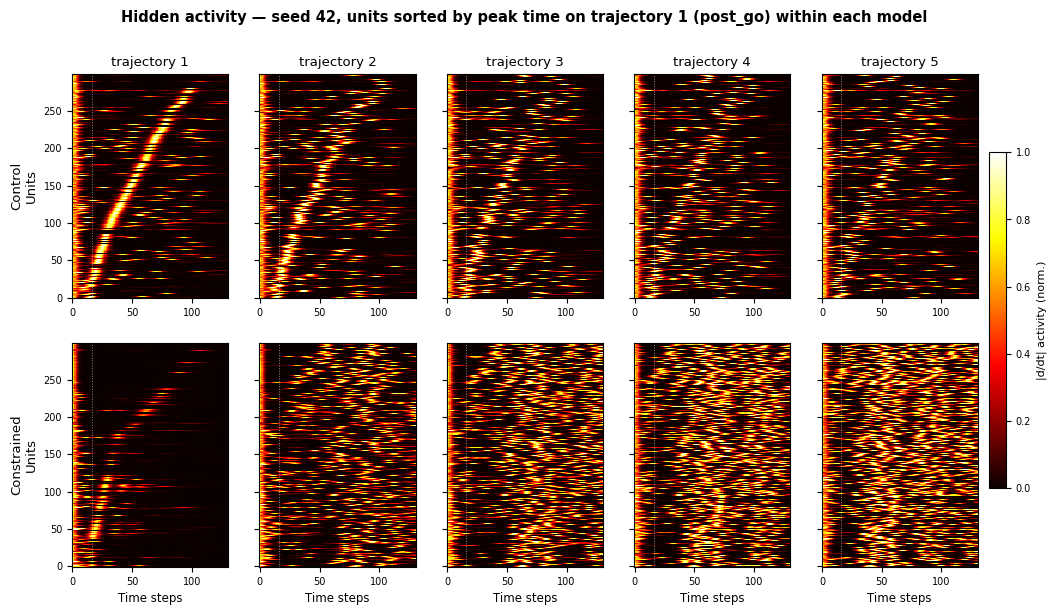

In [23]:
def heat_maps(Hd, mode=HEAT_MODE, sigma=SMOOTH_SIGMA):
    if mode == "rate":
        A = np.abs(np.diff(Hd, axis=2))
        A = gaussian_filter1d(A, sigma=sigma, axis=2, mode="nearest")
        mn = A.min(axis=(0, 2), keepdims=True); mx = A.max(axis=(0, 2), keepdims=True)
    elif mode == "activity":
        A = gaussian_filter1d(Hd, sigma=sigma, axis=2, mode="nearest")
        mn = A.min(axis=2, keepdims=True); mx = A.max(axis=2, keepdims=True)
    else:
        raise ValueError(mode)
    return (A - mn) / np.maximum(mx - mn, 1e-12)

def unit_order(A, ref=REF_DIR, window=SORT_T0):
    t0 = GO_STEP if window == "post_go" else 0
    return np.argsort(np.argmax(A[ref][:, t0:], axis=1))

def fig_heatmaps(R, mode=HEAT_MODE):
    fig, axes = plt.subplots(2, K_MAIN, figsize=(2.25 * K_MAIN + 0.8, 6.4), sharey=True)
    for row, c in enumerate(CONDS):
        A = heat_maps(R[c]["hidden_dir_mean"], mode=mode)
        order = unit_order(A)
        for k in range(K_MAIN):
            ax = axes[row, k]
            im = ax.imshow(A[k][order], aspect="auto", origin="lower", cmap=HEAT_CMAP,
                           vmin=0, vmax=1, interpolation="nearest")
            ax.axvline(GO_STEP, color="w", lw=0.7, ls=":", alpha=0.55)
            if row == 0:
                ax.set_title(f"trajectory {k+1}", fontsize=9.5)
            else:
                ax.set_xlabel("Time steps", fontsize=8.5)
            if k == 0:
                ax.set_ylabel(f"{LAB[c]}\nUnits", fontsize=9.5)
            ax.tick_params(labelsize=7)
    cb = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.018, pad=0.012)
    cb.set_label("|d/dt| activity (norm.)" if mode == "rate" else "activity (per-unit norm.)",
                 fontsize=8)
    cb.ax.tick_params(labelsize=7)
    fig.suptitle(f"Hidden activity — seed {SEED_FIG}, units sorted by peak time on "
                 f"trajectory {REF_DIR + 1} ({SORT_T0}) within each model", fontsize=10.5,
                 fontweight="bold", y=0.98)
    return fig

fig = fig_heatmaps(R)
plt.savefig(f"panel_B_heatmaps_{HEAT_MODE}.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)

## **5. RSM Analysis& Correlation Matrices**

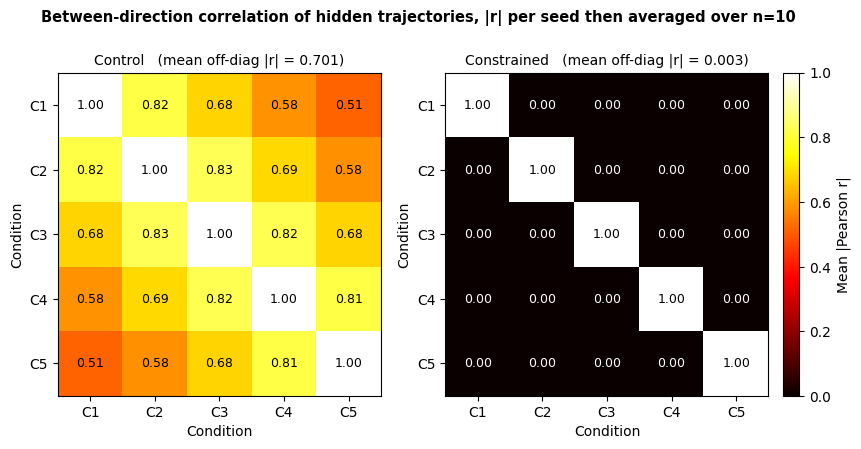

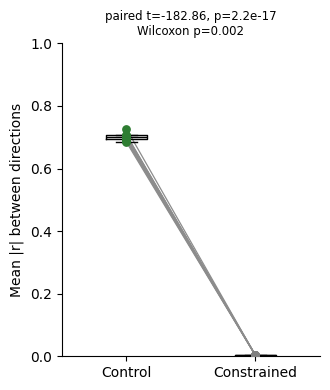

Control     mean|r| = 0.701 +/- 0.012
Constrained mean|r| = 0.003 +/- 0.001


In [24]:
def corr_from_hidden(K, seed, cond):
    H = load_hidden(K, seed, cond)["hid_dir_mean"]        # (K, T, n_h)
    return corr_matrix_np(H)                               # (K, K); signed for "population", |r| for "unit"

Cs = {c: np.stack([corr_from_hidden(K_MAIN, s, c) for s in SEEDS
                   if hid_path(K_MAIN, s, c).exists()]) for c in CONDS}
Cabs  = {c: np.abs(Cs[c]).mean(0) for c in CONDS}          # |r| per seed, THEN mean
Csign = {c: Cs[c].mean(0) for c in CONDS}                  # signed mean, for comparison

iu = np.triu_indices(K_MAIN, 1)
offdiag = {c: np.abs(Cs[c])[:, iu[0], iu[1]].mean(1) for c in CONDS}   # per-seed scalar

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for ax, c in zip(axes, CONDS):
    M = Cabs[c].copy(); np.fill_diagonal(M, np.nan)
    im = ax.imshow(M, cmap=HEAT_CMAP, vmin=0, vmax=1)
    for i in range(K_MAIN):
        for j in range(K_MAIN):
            if i == j:
                ax.text(j, i, "1.00", ha="center", va="center", fontsize=9, color="k")
                continue
            ax.text(j, i, f"{Cabs[c][i, j]:.2f}", ha="center", va="center",
                    fontsize=9, color="k" if Cabs[c][i, j] > .45 else "w")
    ax.set_xticks(range(K_MAIN), [f"C{i+1}" for i in range(K_MAIN)])
    ax.set_yticks(range(K_MAIN), [f"C{i+1}" for i in range(K_MAIN)])
    ax.set_xlabel("Condition"); ax.set_ylabel("Condition")
    ax.set_title(f"{LAB[c]}   (mean off-diag |r| = {offdiag[c].mean():.3f})", fontsize=10)
fig.colorbar(im, ax=axes.tolist(), fraction=0.025, pad=0.02, label="Mean |Pearson r|")
fig.suptitle(f"Between-direction correlation of hidden trajectories, "
             f"|r| per seed then averaged over n={Cs['std'].shape[0]}",
             fontsize=10.5, fontweight="bold", y=1.03)
savefig(fig, "fig03_corr_matrices"); display(fig); plt.close(fig)

fig, ax = plt.subplots(figsize=(3.4, 4.0))
a, b = offdiag["std"], offdiag["con"]
for i in range(len(a)):
    ax.plot([0, 1], [a[i], b[i]], color="0.55", lw=.9, zorder=1)
ax.scatter(np.zeros_like(a), a, color=C_CTL, s=28, zorder=3)
ax.scatter(np.ones_like(b),  b, color=C_CON, s=28, zorder=3)
ax.boxplot([a, b], positions=[0, 1], widths=.32, showfliers=False,
           medianprops=dict(color="k"), zorder=2)
ax.set_xticks([0, 1], ["Control", "Constrained"])
ax.set_ylabel("Mean |r| between directions"); ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
t, p = ttest_rel(b, a); w, pw = wilcoxon(b, a)
ax.set_title(f"paired t={t:.2f}, p={p:.2g}\nWilcoxon p={pw:.2g}", fontsize=8.5)
fig.tight_layout(); savefig(fig, "fig03b_decorrelation_paired")
display(fig); plt.close(fig)

print(f"Control     mean|r| = {a.mean():.3f} +/- {a.std(ddof=1):.3f}")
print(f"Constrained mean|r| = {b.mean():.3f} +/- {b.std(ddof=1):.3f}")

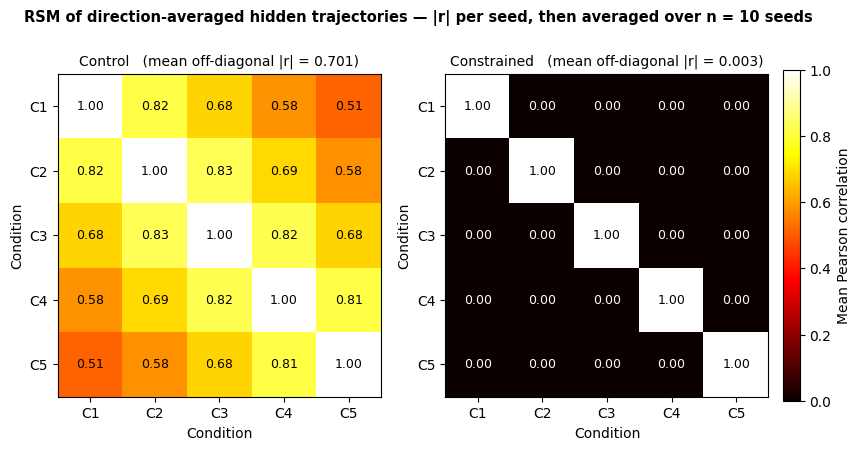

Control       |r| off-diag = 0.7013   signed r off-diag = +0.7013
Constrained   |r| off-diag = 0.0030   signed r off-diag = +0.0030


In [25]:
RSM_ABS    = {c: np.mean([np.abs(RSM_PER_SEED[c][s]) for s in SEEDS], axis=0) for c in CONDS}
RSM_SIGNED = {c: np.mean([RSM_PER_SEED[c][s]         for s in SEEDS], axis=0) for c in CONDS}
RSM_SEM    = {c: np.std([np.abs(RSM_PER_SEED[c][s]) for s in SEEDS], axis=0, ddof=1)
                 / np.sqrt(len(SEEDS)) for c in CONDS}

def fig_rsm(M=RSM_ABS, annotate=True, title=None):
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.3))
    for ax, c in zip(axes, CONDS):
        C = M[c]
        im = ax.imshow(C, cmap=HEAT_CMAP, vmin=0, vmax=1)
        if annotate:
            for i in range(K_MAIN):
                for j in range(K_MAIN):
                    ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=9,
                            color="k" if C[i, j] > 0.45 else "w")
        ax.set_xticks(range(K_MAIN), [f"C{i+1}" for i in range(K_MAIN)])
        ax.set_yticks(range(K_MAIN), [f"C{i+1}" for i in range(K_MAIN)])
        ax.set_xlabel("Condition"); ax.set_ylabel("Condition")
        ax.set_title(f"{LAB[c]}   (mean off-diagonal |r| = {offdiag_mean_abs(C):.3f})",
                     fontsize=10)
    fig.colorbar(im, ax=axes.tolist(), fraction=0.025, pad=0.02,
                 label="Mean Pearson correlation")
    fig.suptitle(title or f"RSM of direction-averaged hidden trajectories — "
                          f"|r| per seed, then averaged over n = {len(SEEDS)} seeds",
                 fontsize=10.5, fontweight="bold", y=1.02)
    return fig

fig = fig_rsm()
ed_savefig(fig, "panel_C_rsm"); display(fig); plt.close(fig)

for c in CONDS:
    iu = np.triu_indices(K_MAIN, 1)
    print(f"{LAB[c]:12s}  |r| off-diag = {RSM_ABS[c][iu].mean():.4f}   "
          f"signed r off-diag = {RSM_SIGNED[c][iu].mean():+.4f}")

## **Epoch statistics**

In [26]:
def first_crossing(curve, L, patience=1):
    c = np.asarray(curve, float) <= L
    if patience == 1:
        idx = np.where(c)[0]
        return int(idx[0] + 1) if idx.size else None
    for i in range(len(c) - patience + 1):
        if c[i:i + patience].all():
            return i + 1
    return None

def band(Ks, margin=MARGIN):
    """PILOT ONLY. On criterion-stopped runs every floor sits at THETA_STOP, so
    this returns the criterion it was handed -- circular. Use THETA_STOP/THETA_HI."""
    sel = {k: v for k, v in RUNS.items() if k[0] in Ks}
    assert sel, f"no runs for K in {Ks}"
    if any(v.get("theta_stop") is not None for v in sel.values()):
        raise RuntimeError(
            "band() called on criterion-stopped runs.")
    floors = {k: float(np.min(v[SIGNAL])) for k, v in sel.items()}
    ceils  = {k: float(np.max(v[SIGNAL])) for k, v in sel.items()}
    lo, hi = max(floors.values()) * (1 + margin), min(ceils.values())
    binding = max(floors, key=floors.get)
    if lo >= hi:
        raise ValueError(f"empty reachable band: lo={lo:.5f} >= hi={hi:.5f}")
    return lo, hi, binding, floors

def stop_report(Ks):
    """Replaces censoring."""
    F = pd.DataFrame([dict(K=k[0], seed=k[1], model=LAB[k[2]],
                           stop_epoch=RUNS[k]["stop_epoch"],
                           cap=MAX_EPOCHS_BY_K[k[0]],
                           frac_of_cap=RUNS[k]["stop_epoch"] / MAX_EPOCHS_BY_K[k[0]],
                           val_at_stop=float(RUNS[k][SIGNAL][-1]),
                           test_at_stop=float(RUNS[k]["test"][-1]))
                      for k in RUNS if k[0] in Ks])
    print(f"criterion theta = {THETA_STOP:.6f}")
    print(F.groupby(["K", "model"])[["stop_epoch", "frac_of_cap", "test_at_stop"]]
           .agg(["mean", "max"]).to_string(float_format=lambda x: f"{x:.4g}"))
    worst = F.loc[F.frac_of_cap.idxmax()]
    if worst.frac_of_cap > 0.9:
        print(">> That run is within 10% of the cap. ")
    return F

def epochs_table(Ks, levels):
    return pd.DataFrame([
        dict(K=K, seed=s, model=LAB[c], level=float(L),
             epochs=first_crossing(RUNS[(K, s, c)][SIGNAL], L, patience=STOP_PATIENCE))
        for (K, s, c) in RUNS if K in Ks for L in levels])

def drop_censored(E, by=("K",)):
    """Kept as a safety net. """
    out = []
    for _, g in E.groupby(list(by)):
        bad = g.loc[g.epochs.isna(), "level"].unique()
        if len(bad):
            print(f"  !! {len(bad)} censored level(s) dropped -- with the frozen grid "
                  f"this should be impossible; check THETA_STOP vs the run floors.")
        out.append(g[~g.level.isin(bad)])
    return pd.concat(out, ignore_index=True)

F_MAIN = stop_report([K_MAIN])

criterion theta = 0.020000
              stop_epoch      frac_of_cap        test_at_stop        
                    mean  max        mean    max         mean     max
K model                                                              
5 Constrained        144  197      0.0576 0.0788      0.01989 0.02036
  Control           41.1   51     0.01644 0.0204      0.01976 0.02013


In [27]:
# grids are frozen, not re-derived from the stopped runs
assert all(RUNS[k]["reached_theta"] for k in RUNS if k[0] == K_MAIN)

LEVELS      = np.array(sorted(map(float, np.geomspace(THETA_HI, THETA_STOP, N_LEVELS)),
                              reverse=True))
LEVELS_FINE = np.geomspace(THETA_HI, THETA_STOP, N_LEVELS_FINE)

E      = epochs_table([K_MAIN], LEVELS)
E_fine = epochs_table([K_MAIN], LEVELS_FINE)
assert E.epochs.notna().all() and E_fine.epochs.notna().all(), \
    ("a run failed to cross a level inside the frozen grid -- impossible unless "
     "THETA_STOP changed since training:\n"
     f"{pd.concat([E, E_fine])[lambda d: d.epochs.isna()].to_string(index=False)}")

E["y"]      = np.log(E.epochs.astype(float))      if LOG_EPOCHS else E.epochs.astype(float)
E_fine["y"] = np.log(E_fine.epochs.astype(float)) if LOG_EPOCHS else E_fine.epochs.astype(float)

THETA_5 = float(THETA_STOP)             
print(f"coarse grid ({E.level.nunique()} levels): "
      f"{[round(x, 5) for x in sorted(E.level.unique(), reverse=True)]}")
print(f"fine grid  : {E_fine.level.nunique()} levels")
print(f"THETA_5 = THETA_STOP = {THETA_5:.6f}")

_chk = E[np.isclose(E.level, THETA_5)].set_index(["seed", "model"])["epochs"]
_ref = (STOPS[STOPS.K == K_MAIN].set_index(["seed", "model"])["stop_epoch"])
_d = (_chk - _ref.reindex(_chk.index)).abs().max()

piv = (E.groupby(["model", "level"])["epochs"].agg(["mean", "std", "count"])
        .reset_index().sort_values(["model", "level"], ascending=[True, False]))
print("\nepochs-to-threshold, mean +/- sd across seeds:")
print(piv.to_string(index=False, float_format=lambda x: f"{x:.1f}"))

coarse grid (6 levels): [np.float64(0.18381), np.float64(0.11795), np.float64(0.07569), np.float64(0.04857), np.float64(0.03117), np.float64(0.02)]
fine grid  : 40 levels
THETA_5 = THETA_STOP = 0.020000

epochs-to-threshold, mean +/- sd across seeds:
      model  level  mean  std  count
Constrained    0.2   1.1  0.3     10
Constrained    0.1   1.5  0.7     10
Constrained    0.1   4.3  2.7     10
Constrained    0.0   8.0  2.9     10
Constrained    0.0  19.1  6.2     10
Constrained    0.0 144.0 33.0     10
    Control    0.2   1.0  0.0     10
    Control    0.1   1.0  0.0     10
    Control    0.1   1.0  0.0     10
    Control    0.0   1.5  1.6     10
    Control    0.0   2.7  1.8     10
    Control    0.0  41.1  7.5     10


## **6. Epoch to Validation MSE** 

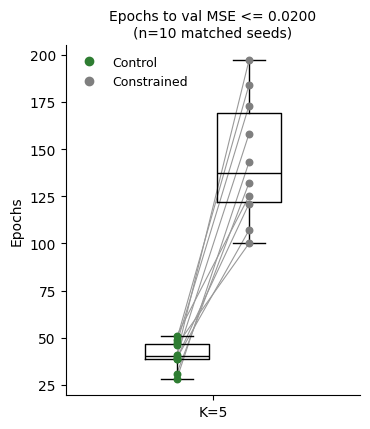

Control        41.1 +/- 7.5 epochs
Constrained   144.0 +/- 33.0 epochs


In [28]:
def paired_epoch_box(ax, groups, labels, title=None, ylab="Epochs"):
    """groups: list of (control_array, constrained_array) per x-group."""
    width, gap = 0.30, 0.90
    centres = np.arange(len(groups)) * 1.0
    for gi, (a, b) in enumerate(groups):
        xa, xb = centres[gi] - width / 2 * gap, centres[gi] + width / 2 * gap
        for i in range(len(a)):
            ax.plot([xa, xb], [a[i], b[i]], color="0.6", lw=.8, zorder=1)
        bp = ax.boxplot([a, b], positions=[xa, xb], widths=width * 0.8,
                        showfliers=False, medianprops=dict(color="k"), zorder=2)
        ax.scatter(np.full(len(a), xa), a, color=C_CTL, s=22, zorder=3)
        ax.scatter(np.full(len(b), xb), b, color=C_CON, s=22, zorder=3)
    ax.set_xticks(centres, labels)
    ax.set_xlim(centres[0] - 0.55, centres[-1] + 0.55)
    ax.set_ylabel(ylab)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=C_CTL, label="Control"),
                       Line2D([], [], marker="o", ls="", color=C_CON, label="Constrained")],
              frameon=False, fontsize=9, loc="upper left")
    if title: ax.set_title(title, fontsize=10)
    return ax

d5 = E[np.isclose(E.level, THETA_5)]
a5 = d5[d5.model == "Control"].set_index("seed")["epochs"].loc[SEEDS].to_numpy(float)
b5 = d5[d5.model == "Constrained"].set_index("seed")["epochs"].loc[SEEDS].to_numpy(float)

fig, ax = plt.subplots(figsize=(3.8, 4.4))
paired_epoch_box(ax, [(a5, b5)], [f"K={K_MAIN}"],
                 title=f"Epochs to val MSE <= {THETA_5:.4f}\n(n={len(a5)} matched seeds)")
fig.tight_layout(); savefig(fig, "fig05_epochs_K5")
display(fig); plt.close(fig)

t, p = ttest_rel(np.log(b5), np.log(a5)) if LOG_EPOCHS else ttest_rel(b5, a5)
_, pw = wilcoxon(b5, a5)
ratio = np.exp(np.mean(np.log(b5) - np.log(a5)))
print(f"Control     {a5.mean():7.1f} +/- {a5.std(ddof=1):.1f} epochs")
print(f"Constrained {b5.mean():7.1f} +/- {b5.std(ddof=1):.1f} epochs")

## **7. Epoch to Threshold-Boxplot**

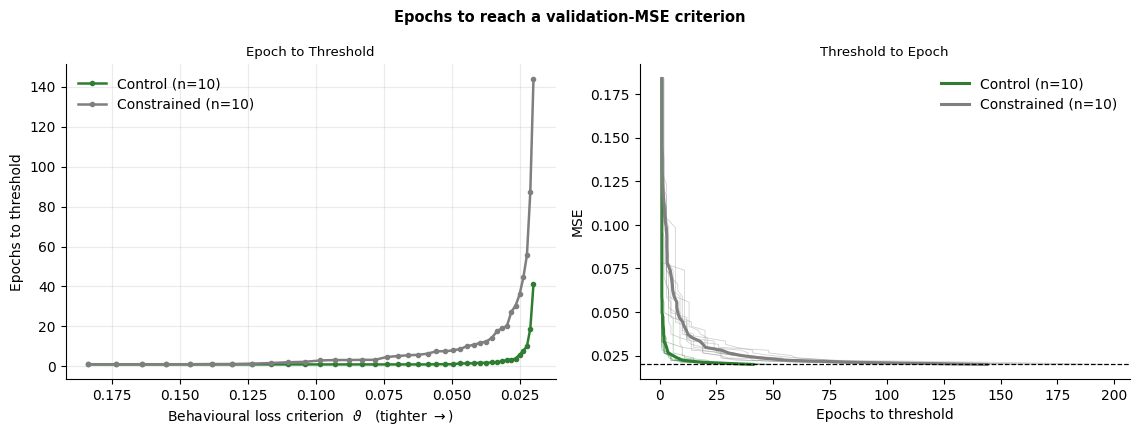

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
for m in ("Control", "Constrained"):
    sub = E_fine[E_fine.model == m]
    g = sub.groupby("level")["epochs"].mean().reset_index().sort_values("level", ascending=False)
    ax.plot(g.level, g.epochs, color=COLOR[m], lw=1.8, marker="o", ms=3,
            label=f"{m} (n={sub.seed.nunique()})")
ax.invert_xaxis()
ax.set_xlabel(r"Behavioural loss criterion  $\vartheta$   (tighter $\rightarrow$)")
ax.set_ylabel("Epochs to threshold"); ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=.25); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Epoch to Threshold", fontsize=9.5)

ax = axes[1]
for m in ("Control", "Constrained"):
    sub = E_fine[E_fine.model == m]
    for s, g in sub.groupby("seed"):
        g = g.sort_values("level", ascending=False)
        ax.plot(g.epochs, g.level, color=COLOR[m], lw=.6, alpha=.35)
    g = sub.groupby("level")["epochs"].mean().reset_index().sort_values("level", ascending=False)
    ax.plot(g.epochs, g.level, color=COLOR[m], lw=2.2,
            label=f"{m} (n={sub.seed.nunique()})")
ax.axhline(E_fine.level.min(), ls="--", color="k", lw=.9)
ax.set_xlabel("Epochs to threshold"); ax.set_ylabel("MSE")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Threshold to Epoch", fontsize=9.5)

fig.suptitle(f"Epochs to reach a validation-MSE criterion", fontsize=10.5, fontweight="bold")
fig.tight_layout(); savefig(fig, "epochs_to_threshold")
display(fig); plt.close(fig)

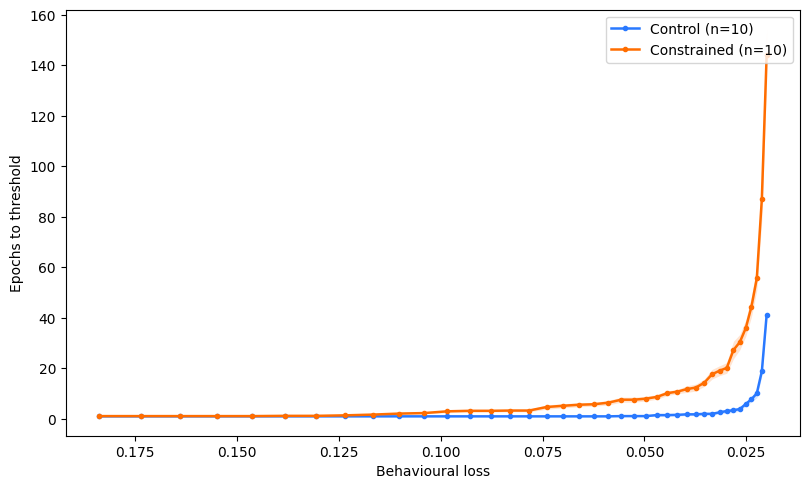

saved -> results_k5_20deg/figs_6391673deb/Fig 5 --- Behavioral Loss (MSE) wrt Epochs --- ( Control vs Constrained ) K5 a1.0.svg
theta 0.02 to 0.1838, 40 levels, n=10/model


In [30]:

MODELS = [("Control", "#2979ff"), ("Constrained", "#ff6d00")]
have = sorted(E_fine.model.unique())
missing = [m for m, _ in MODELS if m not in have]
assert not missing, f"no rows for {missing}; E_fine.model contains {have}"
n_per = E_fine.groupby(["model", "level"]).seed.nunique()
assert n_per.nunique() == 1, f"unbalanced panel, seed counts: {sorted(n_per.unique())}"

FOLDER = FIGDIR                                  
FIGURE = (f"Fig 5 --- Behavioral Loss (MSE) wrt Epochs --- "
          f"( Control vs Constrained ) K{K_MAIN} a{ALPHA}.svg")
PATH = os.path.join(FOLDER, FIGURE)

fig, ax = plt.subplots(figsize=(8.2, 5))
for m, c in MODELS:
    sub = E_fine[E_fine.model == m]
    g = sub.groupby("level")["epochs"].agg(["mean", "sem"]).sort_index(ascending=False)
    ax.plot(g.index, g["mean"], color=c, lw=1.8, marker="o", ms=3,
            label=f"{m} (n={sub.seed.nunique()})")
    ax.fill_between(g.index, g["mean"] - g["sem"], g["mean"] + g["sem"],
                    color=c, alpha=.18, lw=0)

ax.invert_xaxis()                                    # tighter threshold to the right
ax.set_xlabel("Behavioural loss")
ax.set_ylabel("Epochs to threshold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(PATH, format="svg"); plt.savefig(str(PATH)[:-4] + ".png", dpi=200, bbox_inches="tight")
plt.show()
print(f"saved -> {PATH}")
print(f"theta {E_fine.level.min():.4g} to {E_fine.level.max():.4g}, "
      f"{E_fine.level.nunique()} levels, n={n_per.iloc[0]}/model")

## **8. Repeated-measures ANOVA (RM-ANOVA)**

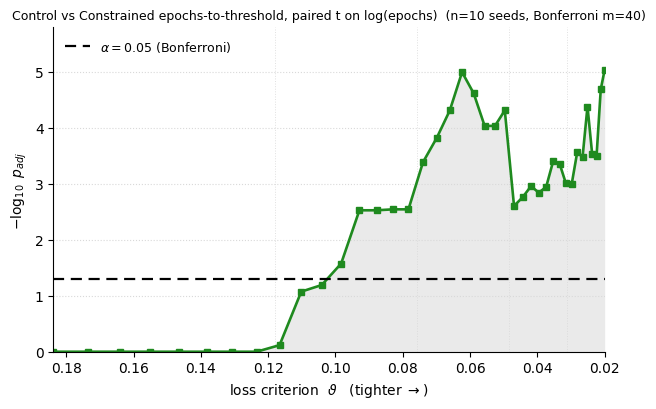

  level  n  ep_ctl  ep_con     t         p    p_bonf
 0.1838 10       1   1.072     1    0.3434         1
 0.1736 10       1   1.072     1    0.3434         1
  0.164 10       1   1.072     1    0.3434         1
  0.155 10       1   1.072     1    0.3434         1
 0.1464 10       1   1.072     1    0.3434         1
 0.1383 10       1   1.149   1.5    0.1679         1
 0.1307 10       1   1.149   1.5    0.1679         1
 0.1234 10       1   1.282 1.893   0.09086         1
 0.1166 10       1   1.534  2.85   0.01908    0.7633
 0.1102 10       1   1.911 4.261   0.00211   0.08438
 0.1041 10       1   2.072 4.447  0.001607    0.0643
0.09832 10       1    2.59 5.077 0.0006656   0.02663
0.09289 10       1   2.891 6.856 7.425e-05   0.00297
0.08775 10       1   2.891 6.856 7.425e-05   0.00297
 0.0829 10       1   2.976  6.89 7.143e-05  0.002857
0.07832 10       1   2.976  6.89 7.143e-05  0.002857
0.07399 10       1   4.145   8.8 1.025e-05 0.0004102
 0.0699 10       1   4.675 9.938 3.768e-06 0.0

In [31]:
rows = []
for L in sorted(E_fine.level.unique(), reverse=True):
    d = E_fine[E_fine.level == L]
    a = d[d.model == "Control"].set_index("seed")["y"]
    b = d[d.model == "Constrained"].set_index("seed")["y"]
    i = a.index.intersection(b.index)
    if len(i) < 3 or not np.any((b.loc[i] - a.loc[i]).to_numpy()):
        continue
    t, p = ttest_rel(b.loc[i], a.loc[i])                # Constrained - Control
    rows.append(dict(level=float(L), n=len(i), t=float(t), p=float(p),
                     ep_ctl=float(np.exp(a.loc[i].mean())),
                     ep_con=float(np.exp(b.loc[i].mean()))))
H = pd.DataFrame(rows, columns=["level", "n", "t", "p", "ep_ctl", "ep_con"])
M_FINE = len(H)
if H.empty:
    raise RuntimeError(
        "no fine criterion has >=3 usable paired seeds -- nothing to test. "
        "Expected in SMOKE mode (n=2 seeds); in a real run it means the epochs "
        "table is empty, so check the censoring report above.")
H["p_bonf"] = np.minimum(H["p"] * M_FINE, 1.0)

fig, ax = plt.subplots(figsize=(6.4, 4.2))
y = -np.log10(H.p_bonf.to_numpy()); x = H.level.to_numpy()
ax.set_axisbelow(True); ax.grid(axis="y", ls=":", color="0.85", lw=.8)
ax.fill_between(x, 0, y, color="0.85", alpha=.55, lw=0)
ax.plot(x, y, color="#1f8a1f", marker="s", ms=4.5, lw=1.9)
ax.axhline(-np.log10(0.05), ls="--", color="k", lw=1.6, dashes=(5, 3))
for L in LEVELS:
    ax.axvline(L, color="0.88", lw=.7, ls=":", zorder=0)
ax.set_xlim(x.max(), x.min()); ax.set_ylim(0, max(y.max() * 1.15, 2))
ax.set_xlabel(r"loss criterion  $\vartheta$   (tighter $\rightarrow$)")
ax.set_ylabel(r"$-\log_{10}\ p_{adj}$")
ax.legend(handles=[Line2D([], [], ls="--", color="k", lw=1.6, dashes=(5, 3),
                          label=r"$\alpha=0.05$ (Bonferroni)")],
          loc="upper left", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Control vs Constrained epochs-to-threshold, paired t on "
             f"{'log(epochs)' if LOG_EPOCHS else 'epochs'}  (n={int(H.n.max())} seeds, "
             f"Bonferroni m={M_FINE})", fontsize=9)
fig.tight_layout(); savefig(fig, "fig07_paired_t_bonferroni")
display(fig); plt.close(fig)

print(H[["level", "n", "ep_ctl", "ep_con", "t", "p", "p_bonf"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4g}"))

In [32]:
if HAVE_PG and E.seed.nunique() >= 3:
    Ea = E.dropna(subset=["epochs"]).copy()
    Ea["level"] = Ea["level"].round(4).astype(str)
    sk = stats.skew(Ea["y"])
    print(f"N = {Ea.seed.nunique()} seeds | DV = {'log(epochs)' if LOG_EPOCHS else 'epochs'} "
          f"| {Ea.level.nunique()} coarse levels | DV skew = {sk:+.2f}\n")
    aov = pg.rm_anova(data=Ea, dv="y", within=["model", "level"], subject="seed",
                      detailed=True, effsize="np2").rename(
                      columns={"p-unc": "p_unc", "p-GG-corr": "p_GG_corr"})
    print(aov[[c for c in ["Source", "F", "p_unc", "p_GG_corr", "np2"] if c in aov]]
          .to_string(index=False))

    post = []
    for L in sorted(Ea.level.unique(), key=float, reverse=True):
        d = Ea[Ea.level == L]
        a = d[d.model == "Control"].set_index("seed")["y"]
        b = d[d.model == "Constrained"].set_index("seed")["y"]
        i = a.index.intersection(b.index)
        t, p = stats.ttest_rel(b.loc[i], a.loc[i])
        _, pw = wilcoxon(b.loc[i], a.loc[i])
        post.append(dict(level=float(L), n=len(i), ep_ctl=float(np.exp(a.loc[i].mean())),
                         ep_con=float(np.exp(b.loc[i].mean())),
                         ratio=float(np.exp((b.loc[i] - a.loc[i]).mean())),
                         t=float(t), p=float(p), p_wilcoxon=float(pw)))
    P = pd.DataFrame(post)
    P["p_bonf"] = np.minimum(P.p * len(P), 1.0)
    print(f"\nper-level paired contrast (Constrained - Control), Bonferroni over "
          f"{len(P)} coarse levels:")
    print(P.to_string(index=False, float_format=lambda x: f"{x:.4g}"))


N = 10 seeds | DV = log(epochs) | 6 coarse levels | DV skew = +0.94

       Source          F        p_unc    p_GG_corr      np2
        model 104.716807 2.952727e-06 2.952727e-06 0.920856
        level 629.761883 1.911087e-40 2.219203e-26 0.985910
model * level  27.253040 1.406796e-12 4.963666e-08 0.751745

per-level paired contrast (Constrained - Control), Bonferroni over 6 coarse levels:
 level  n  ep_ctl  ep_con  ratio     t         p  p_wilcoxon    p_bonf
0.1838 10       1   1.072  1.072     1    0.3434      0.3173         1
0.1179 10       1   1.374  1.374 2.356   0.04292     0.05878    0.2575
0.0757 10       1   3.782  3.782  8.51 1.347e-05    0.001953 8.082e-05
0.0486 10   1.196   7.506  6.275 6.846 7.507e-05    0.003906 0.0004504
0.0312 10   2.259   18.12  8.023 8.054 2.098e-05    0.001953 0.0001259
  0.02 10   40.44   140.6  3.478 13.83 2.278e-07    0.001953 1.367e-06


## **EXPORTS**

In [33]:
if "EPOCHS" not in globals():
    EPOCHS = {c: np.array([int(load_ckpt(ckpt_path(s, c))["stop_epoch"]) for s in SEEDS], dtype=float)
              for c in CONDS}
if "CORR" not in globals():
    CORR = {c: np.array([offdiag_mean_abs(RSM_PER_SEED[c][s]) for s in SEEDS]) for c in CONDS}

np.savez_compressed(
    ARRDIR / f"figure_seed{SEED_FIG}_{SPLIT}.npz",
    predictions_control=R["std"]["pred"], predictions_constrained=R["con"]["pred"],
    labels=R["std"]["labels"], targets=R["std"]["targ"],
    hidden_control=R["std"]["hidden"], hidden_constrained=R["con"]["hidden"],
    hidden_dir_mean_control=R["std"]["hidden_dir_mean"],
    hidden_dir_mean_constrained=R["con"]["hidden_dir_mean"],
    rsm_abs_control=RSM_ABS["std"], rsm_abs_constrained=RSM_ABS["con"],
    rsm_signed_control=RSM_SIGNED["std"], rsm_signed_constrained=RSM_SIGNED["con"],
    epochs_control=EPOCHS["std"], epochs_constrained=EPOCHS["con"],
    corr_control=CORR["std"], corr_constrained=CORR["con"],
    seeds=np.array(SEEDS), go_step=GO_STEP, theta_stop=THETA_STOP,
    eval_seed=EVAL_SEED, cfg_hash=CFG_HASH, split=SPLIT,
)

EXPORT = SUMMARY.copy()
EXPORT["epochs_to_theta"] = EXPORT.apply(
    lambda r_: EPOCHS["std" if r_.model == "Control" else "con"][SEEDS.index(r_.seed)], axis=1)
EXPORT["mean_abs_r"] = EXPORT.apply(
    lambda r_: CORR["std" if r_.model == "Control" else "con"][SEEDS.index(r_.seed)], axis=1)
EXPORT.to_csv(OUT_DIR / "extended_data_metrics.csv", index=False)

if SAVE_HIDDEN_ALL_SEEDS:
    for s in SEEDS:
        for c in CONDS:
            r = extract(s, c, keep_hidden=True)
            np.savez_compressed(ARRDIR / f"K5_s{s}_{c}_{SPLIT}.npz",
                                predictions=r["pred"], labels=r["labels"],
                                hidden=r["hidden"], hidden_dir_mean=r["hidden_dir_mean"])
            del r

print(f"arrays  -> {(ARRDIR / f'figure_seed{SEED_FIG}_{SPLIT}.npz').resolve()}")
print(f"metrics -> {(OUT_DIR / 'extended_data_metrics.csv').resolve()}")
print(f"figures -> {ED_FIGDIR.resolve()}")
print("\n".join(sorted(p.name for p in ED_FIGDIR.glob('*.png'))))

arrays  -> /Users/kevin/Downloads/results_k5_20deg/main_study_6391673deb/extended_data/arrays/figure_seed42_test.npz
metrics -> /Users/kevin/Downloads/results_k5_20deg/main_study_6391673deb/extended_data/extended_data_metrics.csv
figures -> /Users/kevin/Downloads/results_k5_20deg/main_study_6391673deb/extended_data/figures
panel_C_rsm.png


In [34]:
E.to_csv(FIGDIR / "epochs_coarse_K5.csv", index=False)
E_fine.to_csv(FIGDIR / "epochs_fine_K5.csv", index=False)
MSE.to_csv(FIGDIR / "mse_final_K5.csv", index=False)
H.to_csv(FIGDIR / "paired_t_bonferroni_K5.csv", index=False)
pd.DataFrame({LAB[c]: offdiag[c] for c in CONDS}, index=SEEDS[:len(offdiag['std'])]) \
  .to_csv(FIGDIR / "decorrelation_per_seed_K5.csv")

STOPS.to_csv(FIGDIR / "stop_epochs.csv", index=False)

manifest = dict(cfg_hash=CFG_HASH, cfg=CFG, n_runs=len(RUNS),
                seeds=SEEDS, theta_5=float(THETA_5),
                theta_stop=float(THETA_STOP), theta_hi=float(THETA_HI),
                theta_source=THETA_SOURCE, stop_patience=STOP_PATIENCE,
                stop_epochs={f"K{r.K}_s{r.seed}_{r.model}": int(r.stop_epoch)
                             for r in STOPS.itertuples()},
                figures=sorted(p.name for p in FIGDIR.glob("*.png")))
(FIGDIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print(json.dumps({k: v for k, v in manifest.items() if k != "cfg"}, indent=2, default=str))

{
  "cfg_hash": "6391673deb",
  "n_runs": 20,
  "seeds": [
    42,
    123,
    456,
    777,
    999,
    2023,
    31415,
    271828,
    7,
    13
  ],
  "theta_5": 0.02,
  "theta_stop": 0.02,
  "theta_hi": 0.183806,
  "theta_source": "pinned by hand",
  "stop_patience": 5,
  "stop_epochs": {
    "K5_s7_Constrained": 173,
    "K5_s13_Constrained": 100,
    "K5_s42_Constrained": 197,
    "K5_s123_Constrained": 125,
    "K5_s456_Constrained": 184,
    "K5_s777_Constrained": 143,
    "K5_s999_Constrained": 121,
    "K5_s2023_Constrained": 158,
    "K5_s31415_Constrained": 107,
    "K5_s271828_Constrained": 132,
    "K5_s7_Control": 47,
    "K5_s13_Control": 46,
    "K5_s42_Control": 41,
    "K5_s123_Control": 51,
    "K5_s456_Control": 49,
    "K5_s777_Control": 28,
    "K5_s999_Control": 39,
    "K5_s2023_Control": 40,
    "K5_s31415_Control": 39,
    "K5_s271828_Control": 31
  },
  "figures": [
    "Fig 5 --- Behavioral Loss (MSE) wrt Epochs --- ( Control vs Constrained ) K5 a1.0.png